# Zonation / Gradient / Transfer / Metastasis Analysis -- Khaliq et al. 2024 Cohort (Indiana University)

Re-runs the same analysis pipeline built and validated on the Pei et al. 2025 cohort
(`family_transfer_multi_patient-pdac_visium_pei-pancreatic_cancer.ipynb`) on the *other* PDAC
Visium cohort already used in this repo (`pdac_mets_visium_gse272362`, Khaliq et al. 2024, Indiana
University -- see `family_transfer_multi_patient-pdac_mets_visium-pancreatic_cancer.ipynb`, which
this notebook borrows its splat-training/family-clustering recipe from verbatim). Does not modify
or replace that existing notebook -- this is a new, separate analysis reusing the same trained-model
recipe.

**Why this cohort is worth the repeat**: unlike the Pei cohort, this one ships with **real
pathologist per-spot tumor annotations** (`first_type`, `spot_class`). Every validation done on the
Pei cohort (EMT-marker check, family coherence) had to rely on internal consistency or published
aggregate percentages because no per-spot ground truth existed. Here, gradient magnitude and EMT
score can be checked directly against real tumor-vs-non-tumor labels -- a strictly stronger test
than anything possible on the other cohort.

Reuses, unchanged: shared per-patient autoencoder, AE-seeded per-section `AmplitudeSplatField`
training, marker-free transcriptional-gradient field (`torch.func.jacrev`+`vmap` on splat mixing
weights), EMT/dissemination marker check (same literature panel), primary program family
clustering, self-referential z-score transfer distinctiveness (not a significance-threshold gate --
see the Pei-cohort notebook's intro for why), and cross-patient negative-control artifact saving.
Classical/basal and EMT marker lists are imported directly from
`paper.data_loaders.pdac_mets_visium_pei` -- both are literature marker panels, not tied to either
cohort's own data, so reusing them here avoids duplicating the same gene lists.

New in this notebook: gradient magnitude and EMT score are correlated against each active primary
splat's **real, pathologist-derived tumor purity** (fraction of covered real spots labeled
`Tumor Epithelial cells`, via the same `coverage_mask_for_points` ellipse-containment logic already
used in the existing Khaliq-cohort notebook) -- the ground-truth check the Pei-cohort version of
this analysis could not do.

Training requires GPU -- run via SLURM (`scripts/run_gradient_metastasis_khaliq_notebook.slurm`),
not on the login node.

**The idea being tested:** rather than a raw pointwise transcriptional-gradient magnitude (tested in the sibling notebook `gradient_metastasis-pdac_mets_visium-pancreatic_cancer.ipynb`, where it didn't reliably track real tumor purity), this notebook reframes "rate of change" using the standard tumor core-vs-edge design from the spatial-transcriptomics literature: label each splat tumor-like or not from an independent marker panel, then ask whether gradient magnitude and an EMT/dissemination marker score rise specifically as a tumor splat approaches its own edge -- a distance computed purely from the splat field's own continuous geometry, something a fixed real spot grid can't give you directly.

**Headline finding:** both measures rise near the tumor's own edge in this cohort, and -- more importantly -- the same pattern independently replicates in the Pei et al. 2025 cohort (`zonation_metastasis-pdac_visium_pei-pancreatic_cancer.ipynb`, no shared patients or authors with this cohort). The EMT-vs-edge result is the more informative of the two: the gradient-vs-edge result is partly a geometric consistency check (boundaries are, close to by definition, where a fitted mixture changes fastest), while the EMT panel shares no genes with the panel used to call the tumor edge, so that correlation isn't structurally guaranteed.

In [1]:
from pathlib import Path
import os
import sys
import random
import json

os.environ.setdefault('NUMBA_CACHE_DIR', '/tmp/numba_cache')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import torch

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import (
    AmplitudeSplatField,
    DataConfig,
    SplatConfig,
    build_cell_only_targets,
    composition_cosine_loss,
    create_amplitude_splat_optimizer,
    evaluate_count_model,
    farthest_point_sample_indices,
    compute_splat_weights,
    usage_statistics,
    log_total_count_loss,
    mae_count_loss,
    sample_tissue_support,
    GeneProfileAutoencoder,
    evaluate_profile_autoencoder,
    train_profile_autoencoder,
)
from spatsplat.baselines import CountMLP, KNNCountRegressor, MeanProfileBaseline
from paper.data_loaders.pdac_mets_visium import (
    load_pdac_mets_visium_dataset,
    select_pdac_patients,
)
# Classical/basal and EMT marker lists are literature panels, not tied to either cohort's own
# data -- reused directly from the Pei-cohort loader module rather than duplicated.
from paper.data_loaders.pdac_mets_visium_pei import load_classical_basal_markers, load_emt_dissemination_markers

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU available -- spatsplat training must always run on GPU (CPU runs give "
        "divergent/degenerate results). Submit this notebook via SLURM."
    )
device = 'cuda'

BASE_FIGURE_DIR = PROJECT_ROOT / 'figures' / 'zonation_metastasis_khaliq'
BASE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def _slugify_figure_name(text: str) -> str:
    text = (text or '').strip().lower()
    text = ''.join(ch if ch.isalnum() else '_' for ch in text)
    while '__' in text:
        text = text.replace('__', '_')
    return text.strip('_') or 'figure'


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.4g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)

/home/ns5404/.conda/envs/spatsplat/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/ns5404/.conda/envs/spatsplat/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/ns5404/.conda/envs/spatsplat/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


## Parameters

Splat/baseline/AE hyperparameters and family-clustering/transfer thresholds are unchanged from the
Pei-cohort notebook (already validated there, and the splat recipe itself traces back to the
original Khaliq-cohort `family_transfer_multi_patient-pdac_mets_visium-pancreatic_cancer.ipynb`).
Only the patient-selection parameter name changes (`min_tumor_fraction`, matching
`select_pdac_patients`'s own kwarg).

In [2]:
patient_id = "PT_8"
min_tumor_fraction = 0.20  # matches select_pdac_patients kwarg name

random_seed = 1023
plot_point_size = 1.0

baseline_val_fraction = 0.1
baseline_test_fraction = 0.1
baseline_mlp_hidden_dim = 128
baseline_mlp_epochs = 100
baseline_mlp_batch_size = 4096
baseline_mlp_lr = 1e-3
baseline_knn_k = 32

shared_ae_hidden_dim = 128
shared_ae_latent_dim = 32
shared_ae_epochs = 150
shared_ae_batch_size = 1024
shared_ae_lr = 1e-3

splat_init_log_amplitude = 6.0
splat_spots_per_component = 8
splat_min_components = 256
splat_max_components = 640
section_splat_epochs = 150
section_splat_batch_size = 2048
section_splat_means_lr = 5e-3
section_splat_log_scales_lr = 1e-3
section_splat_rotation_lr = 1e-3
section_splat_opacity_lr = 1e-3
section_splat_latents_lr = 1e-3
section_splat_decoder_lr = 1e-3
section_splat_amplitude_lr = 1e-3
section_composition_loss_weight = 1.0
section_total_count_loss_weight = 0.2
section_mae_refine_weight = 1.0
section_mae_refine_fraction = 0.25
section_seed_neighbor_k = 16
section_off_tissue_batch_size = 2048
section_off_tissue_weight = 1e-6
section_center_support_weight = 0.001

active_mean_usage_threshold = 1e-4

primary_family_cosine_threshold = 0.95
primary_family_min_size = 3
max_primary_families_report = 8

# Transfer "distinctiveness": whole-transcriptome composition cosine similarity between any two
# real, biologically plausible profiles in this tissue is compressed into a narrow high range
# (~0.7-0.95) regardless of whether the two profiles are truly the same program or genuinely
# different ones. Two attempts at an absolute-threshold significance test both failed as a
# result, in complementary directions: a gene-label-shuffled null was trivially beaten by any
# coherent profile (100% "significant" everywhere, no discrimination); a real-data null (cosine
# of off-target primary splats to each family prototype) was inflated by near-duplicate
# neighboring families and ended up at least as strict as the real scores (0% "significant"
# everywhere). Rather than a third external-null attempt, distinctiveness is now a continuous,
# self-referential per-splat statistic that needs no external population at all: how many
# standard deviations a splat's best-family score sits above the mean of its own scores to every
# OTHER family. This is immune to the absolute-scale problem by construction.
transfer_family_min_matched_splats = 3
ig_gene_prefixes = ('IGH', 'IGK', 'IGL', 'JCHAIN')
ig_topk = 10
ig_top_gene_fraction_threshold = 0.4

data_cfg = DataConfig(mask_grid_size=128, cell_mask_min_radius=2.5)

set_seed(random_seed)

In [3]:
# Derived from the parameters above -- must run in a cell AFTER the parameters cell so it
# sees papermill's injected override values, not the defaults (papermill injects a new cell
# with the override values immediately AFTER the tagged cell, not in place of it).
patient_pool = select_pdac_patients(min_tumor_fraction=min_tumor_fraction)
if patient_id not in patient_pool:
    raise RuntimeError(
        f"patient_id={patient_id!r} does not qualify (needs a primary section with "
        f">={min_tumor_fraction:.0%} primary tumor-epithelial spot fraction); "
        f"qualifying patients: {sorted(patient_pool)}"
    )
patient_sections = patient_pool[patient_id]
met_roles = sorted(role for role in patient_sections if role != 'primary')

FIGURE_EXPORT_DIR = BASE_FIGURE_DIR / patient_id
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

sample_seed_offsets = {role: idx for idx, role in enumerate(sorted(patient_sections))}


def export_figure_axes(fig, fallback_prefix: str = "figure", dpi: int = 200):
    for ax in fig.axes:
        title = ax.get_title().strip() if hasattr(ax, "get_title") else ""
        if not title:
            continue
        base = _slugify_figure_name(f"{fallback_prefix}_{title}")
        fig.savefig(FIGURE_EXPORT_DIR / f"{base}.png", dpi=dpi, bbox_inches='tight')
        break
    else:
        fig.savefig(FIGURE_EXPORT_DIR / f"{_slugify_figure_name(fallback_prefix)}.png", dpi=dpi, bbox_inches='tight')


def sample_seed(role: str, *, base_seed: int = random_seed) -> int:
    return int(base_seed + 1000 * sample_seed_offsets[role])


def choose_num_splats(n_spots: int) -> int:
    raw_value = int(round(n_spots / splat_spots_per_component))
    return int(np.clip(raw_value, splat_min_components, splat_max_components))


print(f"patient_id={patient_id} | sections: {patient_sections} | met_roles={met_roles}")

patient_id=PT_8 | sections: {'primary': 'IU_PDA_T8', 'lymph_node_met': 'IU_PDA_LNM8', 'liver_sample': 'IU_PDA_HM8'} | met_roles=['liver_sample', 'lymph_node_met']


## Load sections

One `LoadedData` + `BuiltDataset` bundle per section (primary plus every metastatic role for this patient), mirroring the Khaliq multi-patient notebook's `sample_bundles` pattern.

PT_8 | section summary
{'primary': {'sample_title': 'IU_PDA_T8', 'tissue_origin': 'Pancreas', 'n_spots': 3779, 'n_genes': 17893, 'mean_total_count': 2661.0, 'median_total_count': 1899.0, 'num_splats': 472}, 'lymph_node_met': {'sample_title': 'IU_PDA_LNM8', 'tissue_origin': 'Lymph node', 'n_spots': 3407, 'n_genes': 17893, 'mean_total_count': 4093.0, 'median_total_count': 3606.0, 'num_splats': 426}, 'liver_sample': {'sample_title': 'IU_PDA_HM8', 'tissue_origin': 'Liver', 'n_spots': 4032, 'n_genes': 17893, 'mean_total_count': 1490.0, 'median_total_count': 1001.0, 'num_splats': 504}}


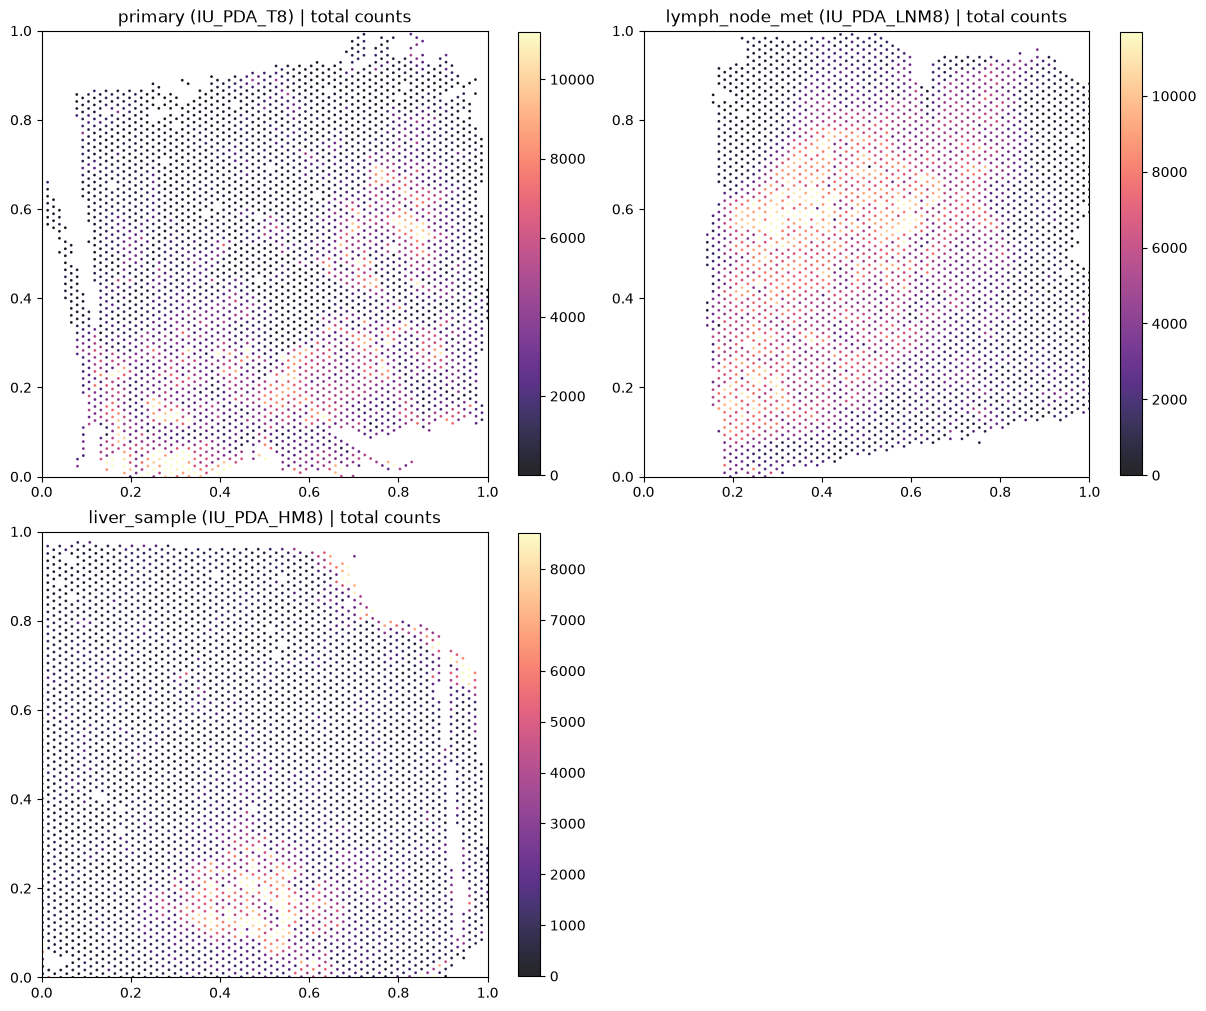

In [4]:
tumor_label = 'Tumor Epithelial cells'


def load_section_bundle(role: str, sample_title: str):
    loaded = load_pdac_mets_visium_dataset(sample_name=sample_title, device=device, config=data_cfg)
    dataset = build_cell_only_targets(loaded, data_cfg)
    adata = loaded.adata
    tumor_first_mask = (
        adata.obs['first_type'].astype(str).eq(tumor_label) & ~adata.obs['spot_class'].astype(str).eq('reject')
    ).to_numpy()

    counts_np = dataset.cell_targets.detach().cpu().numpy().astype(np.float32)
    total_counts_np = counts_np.sum(axis=1, keepdims=True)
    profiles_np = counts_np / np.clip(total_counts_np, 1e-6, None)
    num_splats = choose_num_splats(int(adata.n_obs))

    return {
        'role': role,
        'sample_title': sample_title,
        'loaded': loaded,
        'dataset': dataset,
        'adata': adata,
        'counts': torch.tensor(counts_np, dtype=torch.float32),
        'total_counts': torch.tensor(total_counts_np, dtype=torch.float32),
        'profiles': torch.tensor(profiles_np, dtype=torch.float32),
        'xy_norm': dataset.cell_features.detach().cpu(),
        'xy_raw': adata.obs[['x_centroid', 'y_centroid']].to_numpy(dtype=np.float32),
        'gene_names': list(map(str, adata.var_names)),
        'tissue_origin': str(adata.obs['Origin'].astype(str).mode().iat[0]),
        'tumor_first_mask': tumor_first_mask,
        'off_tissue_points': dataset.off_tissue_points.detach().cpu(),
        'tissue_mask_tensor': dataset.tissue_mask_tensor.detach().cpu(),
        'num_splats': num_splats,
        'splat_cfg': SplatConfig(
            num_splats=num_splats, latent_dim=shared_ae_latent_dim, hidden_dim=shared_ae_hidden_dim,
            init_log_scale=-4.5, kernel_sharpness=1.0,
        ),
        'split_seed': sample_seed(role),
    }


section_bundles = {role: load_section_bundle(role, sample_title) for role, sample_title in patient_sections.items()}

section_summary = {
    role: {
        'sample_title': bundle['sample_title'],
        'tissue_origin': bundle['tissue_origin'],
        'n_spots': int(bundle['adata'].n_obs),
        'n_genes': int(bundle['adata'].n_vars),
        'mean_total_count': float(bundle['counts'].sum(dim=1).mean().item()),
        'median_total_count': float(torch.median(bundle['counts'].sum(dim=1)).item()),
        'num_splats': int(bundle['num_splats']),
    }
    for role, bundle in section_bundles.items()
}
print(f'{patient_id} | section summary')
print(format_for_display(section_summary))

n_cols = 2
n_rows = int(np.ceil(len(section_bundles) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows), constrained_layout=True, squeeze=False)
for idx, (role, bundle) in enumerate(section_bundles.items()):
    ax = axes[idx // n_cols][idx % n_cols]
    points_np = bundle['xy_norm'].numpy()
    total_counts_np = bundle['counts'].sum(dim=1).numpy()
    vmax = np.quantile(total_counts_np, 0.99) if len(total_counts_np) else 1.0
    scat = ax.scatter(points_np[:, 0], points_np[:, 1], c=total_counts_np, s=plot_point_size, cmap='magma', alpha=0.85, vmin=0, vmax=vmax)
    ax.set_title(f'{role} ({bundle["sample_title"]}) | total counts')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    fig.colorbar(scat, ax=ax, fraction=0.046, pad=0.04)
for idx in range(len(section_bundles), n_rows * n_cols):
    axes[idx // n_cols][idx % n_cols].axis('off')
export_figure_axes(fig, fallback_prefix='tissue_overview')
plt.show()

## Splits and baselines

Same mean-profile / KNN / MLP baselines every reconstruction notebook in this repo reports, one set per section.

In [5]:
def make_section_split_indices(n, val_fraction=baseline_val_fraction, test_fraction=baseline_test_fraction, seed=random_seed):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    n_test = min(max(int(round(test_fraction * n)), 1), max(1, n - 2))
    n_val = min(max(int(round(val_fraction * n)), 1), max(1, n - n_test - 1))
    test_idx = perm[:n_test]
    val_idx = perm[n_test:n_test + n_val]
    train_idx = perm[n_test + n_val:]
    return {
        'train': torch.tensor(train_idx, dtype=torch.long),
        'val': torch.tensor(val_idx, dtype=torch.long),
        'test': torch.tensor(test_idx, dtype=torch.long),
    }


section_splits = {role: make_section_split_indices(bundle['xy_norm'].shape[0], seed=bundle['split_seed']) for role, bundle in section_bundles.items()}


def train_section_mlp(section_xy, section_counts, split_idx, *, seed):
    set_seed(seed)
    model = CountMLP(input_dim=2, hidden_dim=baseline_mlp_hidden_dim, output_dim=section_counts.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=baseline_mlp_lr)
    xy, counts = section_xy.to(device), section_counts.to(device)
    train_idx, val_idx = split_idx['train'].to(device), split_idx['val'].to(device)
    for epoch in range(baseline_mlp_epochs):
        model.train()
        perm = train_idx[torch.randperm(len(train_idx), device=device)]
        for start in range(0, len(perm), baseline_mlp_batch_size):
            idx = perm[start:start + baseline_mlp_batch_size]
            pred_log_rate = model(xy[idx])
            loss = mae_count_loss(pred_log_rate, counts[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
    summary = {name: evaluate_count_model(model, xy, counts, idx.to(device), loss_fn=mae_count_loss) for name, idx in split_idx.items()}
    return {'model': model, 'summary': summary}


def build_section_knn(section_xy, section_counts, split_idx, *, k=baseline_knn_k):
    xy, counts = section_xy.detach().cpu(), section_counts.detach().cpu()
    train_idx = split_idx['train'].detach().cpu()
    model = KNNCountRegressor(xy[train_idx], counts[train_idx], k=k)
    summary = {name: evaluate_count_model(model, xy, counts, idx.detach().cpu(), loss_fn=mae_count_loss) for name, idx in split_idx.items()}
    return {'model': model, 'summary': summary}


def build_section_mean_baseline(section_xy, section_counts, split_idx):
    xy, counts = section_xy.to(device), section_counts.to(device)
    train_idx = split_idx['train'].to(device)
    model = MeanProfileBaseline(counts[train_idx])
    summary = {name: evaluate_count_model(model, xy, counts, idx.to(device), loss_fn=mae_count_loss) for name, idx in split_idx.items()}
    return {'model': model, 'summary': summary}


baseline_field_results = {}
for offset, (role, bundle) in enumerate(section_bundles.items()):
    split_idx = section_splits[role]
    mlp_result = train_section_mlp(bundle['xy_norm'], bundle['counts'], split_idx, seed=random_seed + 100 + offset)
    mean_result = build_section_mean_baseline(bundle['xy_norm'], bundle['counts'], split_idx)
    knn_result = build_section_knn(bundle['xy_norm'], bundle['counts'], split_idx)
    baseline_field_results[role] = {'Mean baseline': mean_result, 'MLP-MAE': mlp_result, 'KNN': knn_result}

baseline_summary = {role: {name: r['summary']['test'] for name, r in results.items()} for role, results in baseline_field_results.items()}
print(f'{patient_id} | baseline test-split summary')
print(format_for_display(baseline_summary))

PT_8 | baseline test-split summary
{'primary': {'Mean baseline': {'loss': 0.2097, 'mae': 0.2097, 'n': 378}, 'MLP-MAE': {'loss': 0.1539, 'mae': 0.1539, 'n': 378}, 'KNN': {'loss': 0.1845, 'mae': 0.1845, 'n': 378}}, 'lymph_node_met': {'Mean baseline': {'loss': 0.2871, 'mae': 0.2871, 'n': 341}, 'MLP-MAE': {'loss': 0.2261, 'mae': 0.2261, 'n': 341}, 'KNN': {'loss': 0.2383, 'mae': 0.2383, 'n': 341}}, 'liver_sample': {'Mean baseline': {'loss': 0.1197, 'mae': 0.1197, 'n': 403}, 'MLP-MAE': {'loss': 0.07841, 'mae': 0.07841, 'n': 403}, 'KNN': {'loss': 0.1057, 'mae': 0.1057, 'n': 403}}}


## Shared profile autoencoder

Trained once on the union of every section's normalized profiles, then reused (frozen decoder weights copied in) to seed every section's splat field -- this is what makes splat programs comparable across sections, unlike training a separate AE per section.

PT_8 | shared AE summary
{'train': {'loss': 8.338, 'mae': 7.028e-05, 'cosine': 0.798, 'n': 8974}, 'val': {'loss': 8.357, 'mae': 7.021e-05, 'cosine': 0.7956, 'n': 1122}, 'test': {'loss': 8.315, 'mae': 7.086e-05, 'cosine': 0.7957, 'n': 1122}}


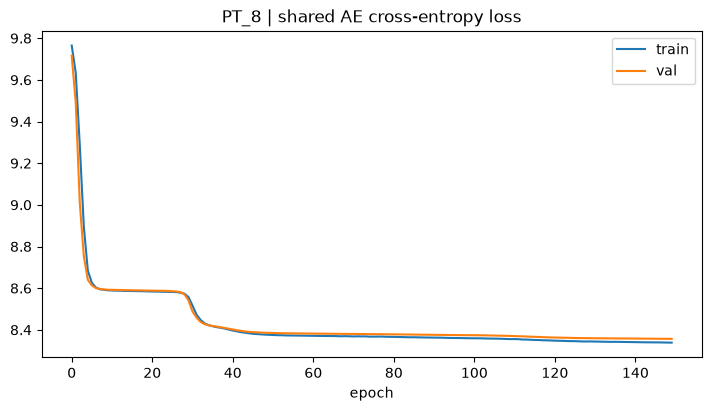

In [6]:
combined_profiles = torch.cat([bundle['profiles'] for bundle in section_bundles.values()], dim=0)
combined_split_idx = make_section_split_indices(combined_profiles.shape[0], seed=random_seed + 300)

set_seed(random_seed + 301)
shared_profile_autoencoder = GeneProfileAutoencoder(
    num_genes=combined_profiles.shape[1], hidden_dim=shared_ae_hidden_dim, latent_dim=shared_ae_latent_dim,
).to(device)
shared_ae_opt = torch.optim.Adam(shared_profile_autoencoder.parameters(), lr=shared_ae_lr)

shared_ae_history = train_profile_autoencoder(
    shared_profile_autoencoder, combined_profiles, combined_split_idx['train'], combined_split_idx['val'],
    epochs=shared_ae_epochs, batch_size=shared_ae_batch_size, optimizer=shared_ae_opt, max_grad_norm=5.0,
)

shared_ae_summary = {
    name: evaluate_profile_autoencoder(shared_profile_autoencoder, combined_profiles, idx, batch_size=shared_ae_batch_size)
    for name, idx in combined_split_idx.items()
}
print(f'{patient_id} | shared AE summary')
print(format_for_display(shared_ae_summary))

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(shared_ae_history['train_loss'], label='train')
ax.plot(shared_ae_history['val_loss'], label='val')
ax.set_title(f'{patient_id} | shared AE cross-entropy loss')
ax.set_xlabel('epoch')
ax.legend()
export_figure_axes(fig, fallback_prefix='shared_ae_training')
plt.show()

## Per-section splat fields

One AE-neighbor `AmplitudeSplatField` per section, all seeded from and sharing decoder weights with
the same `shared_profile_autoencoder` above -- same loss recipe validated on both cohorts
(composition-cosine dominant term + total-count term + off-tissue/center-support regularizers, with
a final MAE-refinement phase in the last 25% of epochs).

PT_8 | splat field summary (test split)
{'primary': {'sample_title': 'IU_PDA_T8', 'num_splats': 472, 'test': {'loss': 0.1657, 'mae': 0.1657, 'n': 378}}, 'lymph_node_met': {'sample_title': 'IU_PDA_LNM8', 'num_splats': 426, 'test': {'loss': 0.2148, 'mae': 0.2148, 'n': 341}}, 'liver_sample': {'sample_title': 'IU_PDA_HM8', 'num_splats': 504, 'test': {'loss': 0.09333, 'mae': 0.09333, 'n': 403}}}
PT_8 | test MAE comparison
                    Mean       KNN       MLP     Splat
role                                                  
primary         0.209701  0.184465  0.153945  0.165694
lymph_node_met  0.287062  0.238292  0.226057  0.214798
liver_sample    0.119659  0.105713  0.078411  0.093335


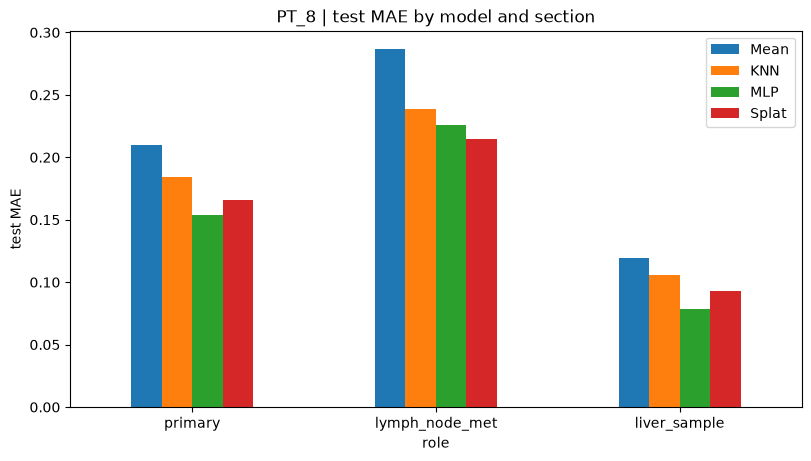

In [7]:
def init_section_splat_model(section_xy, section_profiles, section_total_counts, *, splat_cfg):
    num_splats = int(splat_cfg.num_splats)
    with torch.no_grad():
        xy = section_xy.to(device)
        profiles = section_profiles.to(device)
        total_counts = section_total_counts.to(device)
        seed_idx = farthest_point_sample_indices(xy, num_splats)
        seed_xy = xy[seed_idx]
        pairwise_dist = torch.cdist(seed_xy, xy)
        neighbor_k = min(section_seed_neighbor_k, xy.shape[0])
        _, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)

        neighbor_profiles = profiles[neighbor_idx]
        neighbor_totals = total_counts[neighbor_idx]
        avg_profiles = neighbor_profiles.mean(dim=1)
        avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
        avg_totals = neighbor_totals.mean(dim=1)
        encoded_seed_latents = shared_profile_autoencoder.encoder(avg_profiles)

    model = AmplitudeSplatField(
        num_splats=splat_cfg.num_splats, latent_dim=splat_cfg.latent_dim, hidden_dim=splat_cfg.hidden_dim,
        num_genes=section_profiles.shape[1], init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness, top_k_splats=splat_cfg.top_k_splats,
        init_log_amplitude=splat_init_log_amplitude,
    ).to(device)

    with torch.no_grad():
        model.means.copy_(seed_xy)
        model.latents.copy_(encoded_seed_latents)
        model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
        model.log_scales.fill_(splat_cfg.init_log_scale)
        model.rotation.zero_()
        model.opacity_logits.zero_()
        model.decoder.load_state_dict(shared_profile_autoencoder.decoder.state_dict())

    return model


def evaluate_section_splat_model(model, section_xy, section_counts, split_idx, batch_size=2048):
    was_training = model.training
    model.eval()
    total_loss, total_mae, total_seen = 0.0, 0.0, 0
    xy, counts = section_xy.to(device), section_counts.to(device)
    with torch.no_grad():
        for start in range(0, len(split_idx), batch_size):
            idx = split_idx[start:start + batch_size].to(device)
            pred_log_rate = model(xy[idx])
            loss = mae_count_loss(pred_log_rate, counts[idx])
            pred_counts = torch.exp(pred_log_rate)
            mae = (pred_counts - counts[idx]).abs().mean()
            total_loss += loss.item() * len(idx)
            total_mae += mae.item() * len(idx)
            total_seen += len(idx)
    if was_training:
        model.train()
    return {'loss': total_loss / total_seen, 'mae': total_mae / total_seen, 'n': total_seen}


def train_section_splat_model(section_xy, section_counts, split_idx, initial_model, *, seed, off_tissue_points, tissue_mask_tensor):
    set_seed(seed)
    model = initial_model
    optimizer = create_amplitude_splat_optimizer(
        model, means_lr=section_splat_means_lr, log_scales_lr=section_splat_log_scales_lr,
        rotation_lr=section_splat_rotation_lr, opacity_lr=section_splat_opacity_lr,
        latents_lr=section_splat_latents_lr, decoder_lr=section_splat_decoder_lr, amplitude_lr=section_splat_amplitude_lr,
    )
    history = {'train_joint_loss': [], 'val_loss': [], 'val_mae': []}
    train_idx = split_idx['train'].to(device)
    xy, counts = section_xy.to(device), section_counts.to(device)
    off_tissue_points = off_tissue_points.to(device)
    tissue_mask_tensor = tissue_mask_tensor.to(device)
    mae_refine_start_epoch = max(0, int(round((1.0 - section_mae_refine_fraction) * section_splat_epochs)))

    for epoch in range(section_splat_epochs):
        model.train()
        mae_refine_active = epoch >= mae_refine_start_epoch
        perm = train_idx[torch.randperm(len(train_idx), device=device)]
        off_perm = torch.randperm(len(off_tissue_points), device=device) if len(off_tissue_points) > 0 else None
        running_joint = 0.0
        steps = 0
        for step, start in enumerate(range(0, len(perm), section_splat_batch_size)):
            idx = perm[start:start + section_splat_batch_size]
            pred_log_rate = model(xy[idx])
            cell_loss = mae_count_loss(pred_log_rate, counts[idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(torch.exp(pred_log_rate), counts[idx])
            total_count_loss = log_total_count_loss(pred_log_rate, counts[idx])
            if off_perm is not None and len(off_tissue_points) > 0:
                off_start = (step * section_off_tissue_batch_size) % len(off_perm)
                off_idx = off_perm[off_start:off_start + section_off_tissue_batch_size]
                if len(off_idx) == 0:
                    off_idx = off_perm[:section_off_tissue_batch_size]
                off_tissue_loss = model.total_intensity(off_tissue_points[off_idx]).mean()
            else:
                off_tissue_loss = pred_log_rate.new_tensor(0.0)
            center_support_loss = (1.0 - sample_tissue_support(model.means, tissue_mask_tensor)).mean()

            loss = (
                section_mae_refine_weight * cell_loss
                + section_composition_loss_weight * composition_loss
                + section_total_count_loss_weight * total_count_loss
                + section_off_tissue_weight * off_tissue_loss
                + section_center_support_weight * center_support_loss
            )
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            with torch.no_grad():
                model.means.clamp_(0.0, 1.0)
                model.log_scales.clamp_(-8.0, -2.0)
            running_joint += loss.item()
            steps += 1

        val_summary = evaluate_section_splat_model(model, section_xy, section_counts, split_idx['val'])
        history['train_joint_loss'].append(running_joint / max(steps, 1))
        history['val_loss'].append(val_summary['loss'])
        history['val_mae'].append(val_summary['mae'])

    summary = {name: evaluate_section_splat_model(model, section_xy, section_counts, idx) for name, idx in split_idx.items()}
    return {'model': model, 'history': history, 'summary': summary}


section_splat_results = {}
for offset, (role, bundle) in enumerate(section_bundles.items()):
    split_idx = section_splits[role]
    init_model = init_section_splat_model(bundle['xy_norm'], bundle['profiles'], bundle['total_counts'], splat_cfg=bundle['splat_cfg'])
    result = train_section_splat_model(
        bundle['xy_norm'], bundle['counts'], split_idx, init_model,
        seed=random_seed + 700 + offset * 100,
        off_tissue_points=bundle['off_tissue_points'], tissue_mask_tensor=bundle['tissue_mask_tensor'],
    )
    section_splat_results[role] = result

splat_field_summary = {
    role: {'sample_title': bundle['sample_title'], 'num_splats': int(bundle['num_splats']), 'test': section_splat_results[role]['summary']['test']}
    for role, bundle in section_bundles.items()
}
print(f'{patient_id} | splat field summary (test split)')
print(format_for_display(splat_field_summary))

comparison_rows = []
for role in section_bundles:
    comparison_rows.append({
        'role': role,
        'Mean': baseline_field_results[role]['Mean baseline']['summary']['test']['mae'],
        'KNN': baseline_field_results[role]['KNN']['summary']['test']['mae'],
        'MLP': baseline_field_results[role]['MLP-MAE']['summary']['test']['mae'],
        'Splat': section_splat_results[role]['summary']['test']['mae'],
    })
comparison_df = pd.DataFrame(comparison_rows).set_index('role')
print(f'{patient_id} | test MAE comparison')
print(comparison_df.to_string())

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
comparison_df.plot(kind='bar', ax=ax)
ax.set_ylabel('test MAE')
ax.set_title(f'{patient_id} | test MAE by model and section')
ax.tick_params(axis='x', rotation=0)
export_figure_axes(fig, fallback_prefix='model_comparison')
plt.show()

## Splat utilization

How many splats are actually active per section, before trusting anything downstream.

In [8]:
splat_utilization_summary = {}
active_splat_indices = {}
for role, bundle in section_bundles.items():
    model = section_splat_results[role]['model']
    xy = bundle['xy_norm'].to(device)
    with torch.no_grad():
        weights = compute_splat_weights(model, xy)
        usage = usage_statistics(weights)
        mean_usage_np = weights.mean(dim=0).detach().cpu().numpy()
    active_idx = np.flatnonzero(mean_usage_np > active_mean_usage_threshold)
    active_splat_indices[role] = active_idx
    splat_utilization_summary[role] = {
        'num_splats': int(model.num_splats),
        'active_splats': int(len(active_idx)),
        'active_fraction_gt_1e4': float(usage['active_fraction']),
        'avg_splats_per_query_gt_1pct': float(usage['avg_splats_per_query_gt_1pct']),
    }

print(f'{patient_id} | splat utilization by section')
print(format_for_display(splat_utilization_summary))

PT_8 | splat utilization by section
{'primary': {'num_splats': 472, 'active_splats': 471, 'active_fraction_gt_1e4': 0.9979, 'avg_splats_per_query_gt_1pct': 1.793}, 'lymph_node_met': {'num_splats': 426, 'active_splats': 424, 'active_fraction_gt_1e4': 0.9953, 'avg_splats_per_query_gt_1pct': 1.791}, 'liver_sample': {'num_splats': 504, 'active_splats': 503, 'active_fraction_gt_1e4': 0.998, 'avg_splats_per_query_gt_1pct': 1.75}}


## Splat lineage scoring (classical / basal / plasticity)

Score every active splat's decoded expression (`splat_rates()`) against the Table S4 classical/basal
markers, per section, using the same `sc.tl.score_genes` + normalize/log1p pipeline validated
against the published Table S6 percentages in
`lineage_scoring_validation-pdac_visium_pei-pancreatic_cancer.ipynb`. `plasticity_score = basal_score
- classical_score` is continuous by construction. As before, `score_genes`'s control-gene selection
is computed per-section (over that section's own active-splat population), so scores are internally
comparable within a section but not on an identical scale across sections -- direction and relative
ranking are the meaningful comparison, not raw magnitude equality.

In [9]:
classical_genes, basal_genes = load_classical_basal_markers()

section_lineage_dfs = {}
section_marker_availability = {}
for role, bundle in section_bundles.items():
    model = section_splat_results[role]['model']
    active_idx = active_splat_indices[role]
    gene_names = bundle['gene_names']

    with torch.no_grad():
        splat_rates_np = model.splat_rates().detach().cpu().numpy().astype(np.float32)
        means_np = model.means.detach().cpu().numpy()

    splat_adata = ad.AnnData(X=splat_rates_np[active_idx])
    splat_adata.var_names = pd.Index(gene_names, dtype=str)
    splat_adata.var_names_make_unique()
    sc.pp.normalize_total(splat_adata, target_sum=1e4)
    sc.pp.log1p(splat_adata)

    avail_classical = [g for g in classical_genes if g in splat_adata.var_names]
    avail_basal = [g for g in basal_genes if g in splat_adata.var_names]
    section_marker_availability[role] = (avail_classical, avail_basal)
    sc.tl.score_genes(splat_adata, avail_classical, score_name='classical_score', random_state=0)
    sc.tl.score_genes(splat_adata, avail_basal, score_name='basal_score', random_state=0)

    classical_score = splat_adata.obs['classical_score'].to_numpy()
    basal_score = splat_adata.obs['basal_score'].to_numpy()
    plasticity_score = basal_score - classical_score
    lineage_call = np.where(
        classical_score - basal_score >= 0.3, 'Classical',
        np.where(basal_score - classical_score >= 0.3, 'Basal', 'Intermediate'),
    )

    section_lineage_dfs[role] = pd.DataFrame({
        'patient_id': patient_id,
        'role': role,
        'sample_title': bundle['sample_title'],
        'tissue_origin': bundle['tissue_origin'],
        'splat_idx': active_idx,
        'x_norm': means_np[active_idx, 0],
        'y_norm': means_np[active_idx, 1],
        'classical_score': classical_score,
        'basal_score': basal_score,
        'plasticity_score': plasticity_score,
        'lineage_call': lineage_call,
    })

all_lineage_df = pd.concat(section_lineage_dfs.values(), ignore_index=True)

lineage_call_counts = (
    all_lineage_df.groupby(['role', 'lineage_call']).size().unstack(fill_value=0)
)
plasticity_by_section = all_lineage_df.groupby('role')['plasticity_score'].agg(['mean', 'median', 'std', 'count'])
print(f'{patient_id} | lineage call counts by section')
print(lineage_call_counts.to_string())
print(f'\n{patient_id} | plasticity score by section')
print(plasticity_by_section.to_string())

PT_8 | lineage call counts by section
lineage_call    Basal  Classical  Intermediate
role                                          
liver_sample        0          0           503
lymph_node_met      0        245           179
primary             2        231           238

PT_8 | plasticity score by section
                    mean    median       std  count
role                                               
liver_sample   -0.027944 -0.023429  0.035416    503
lymph_node_met -0.495204 -0.422041  0.372491    424
primary        -0.306235 -0.290366  0.274595    471


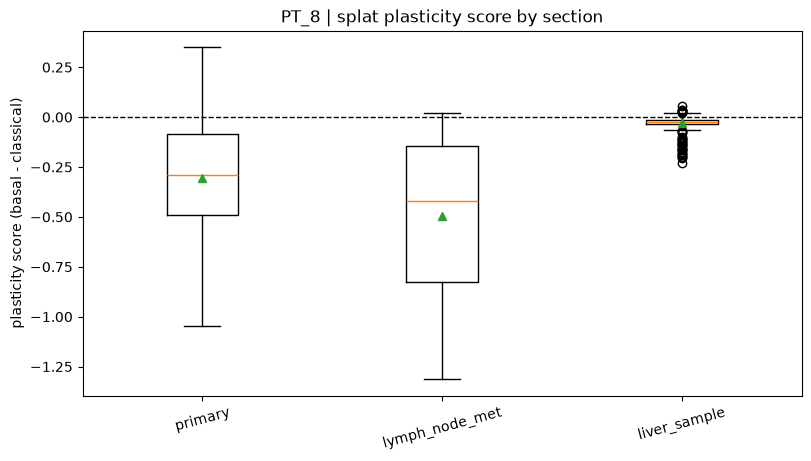

Saved 1398 splat lineage scores to /home/ns5404/singh_research/spatsplat_project/spatsplat/figures/zonation_metastasis_khaliq/PT_8/splat_lineage_scores.csv


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
roles_ordered = list(section_bundles.keys())
box_data = [section_lineage_dfs[role]['plasticity_score'].to_numpy() for role in roles_ordered]
bp = ax.boxplot(box_data, tick_labels=roles_ordered, showmeans=True)
ax.axhline(0.0, color='black', linestyle='--', linewidth=1)
ax.set_ylabel('plasticity score (basal - classical)')
ax.set_title(f'{patient_id} | splat plasticity score by section')
ax.tick_params(axis='x', rotation=15)
export_figure_axes(fig, fallback_prefix='plasticity_by_section')
plt.show()

lineage_out_dir = FIGURE_EXPORT_DIR
all_lineage_df.to_csv(lineage_out_dir / 'splat_lineage_scores.csv', index=False)
print(f'Saved {len(all_lineage_df)} splat lineage scores to {lineage_out_dir / "splat_lineage_scores.csv"}')

### Continuous decoded plasticity field, all sections

Same pattern as `maturity_field-visium-embryonic_mouse_brain.ipynb`'s "Splat Reconstructed Maturity
Field" section, applied here: decode each section's trained field directly on a dense grid (no
per-splat aggregation, no threshold -- the model queried at arbitrary points, masked to tissue
support) and lay every section out side by side. This is the fully continuous counterpart to the
per-splat `plasticity_score` above, and the clearest single figure for comparing where basal- vs.
classical-leaning signal actually sits spatially across primary vs. every metastatic site in one
patient. Uses a simple unnormalized marker-mass fraction rather than `score_genes` (which needs a
population of profiles to pick control genes, not a single query point) -- same tradeoff as the
single-sample notebook's version of this figure.

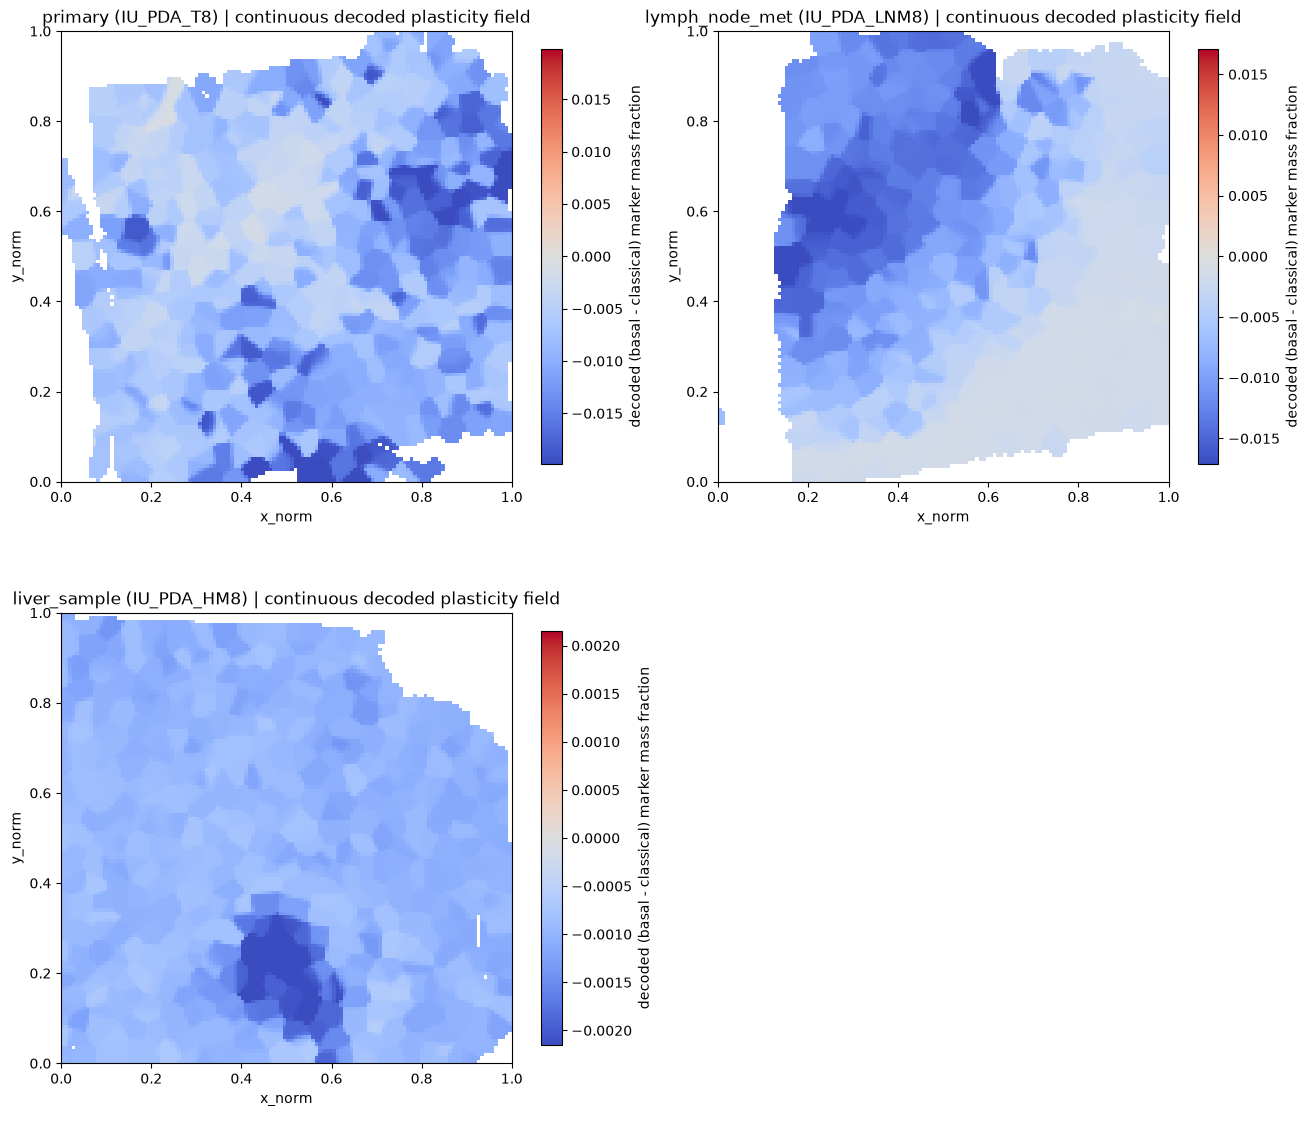

In [11]:
grid_size = 128
grid_query_batch_size = 4096
grid_mask_threshold = 0.05

section_grid_plasticity = {}
n_cols = 2
n_rows = int(np.ceil(len(section_bundles) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5 * n_cols, 5.8 * n_rows), constrained_layout=True, squeeze=False)

for idx, role in enumerate(section_bundles):
    bundle = section_bundles[role]
    model = section_splat_results[role]['model']
    avail_classical, avail_basal = section_marker_availability[role]
    gene_name_list = bundle['gene_names']
    classical_gene_idx = torch.tensor([gene_name_list.index(g) for g in avail_classical], device=device, dtype=torch.long)
    basal_gene_idx = torch.tensor([gene_name_list.index(g) for g in avail_basal], device=device, dtype=torch.long)
    tissue_mask_d = bundle['tissue_mask_tensor'].to(device)

    grid_x = torch.linspace(0.0, 1.0, grid_size, device=device)
    grid_y = torch.linspace(0.0, 1.0, grid_size, device=device)
    mesh_y, mesh_x = torch.meshgrid(grid_y, grid_x, indexing='ij')
    grid_xy = torch.stack([mesh_x.reshape(-1), mesh_y.reshape(-1)], dim=1)

    with torch.no_grad():
        grid_mask_score = sample_tissue_support(grid_xy, tissue_mask_d).reshape(grid_size, grid_size).cpu().numpy()
        grid_mask_bool = grid_mask_score > grid_mask_threshold

        grid_plasticity_chunks = []
        for start in range(0, len(grid_xy), grid_query_batch_size):
            batch_xy = grid_xy[start:start + grid_query_batch_size]
            batch_pred = torch.exp(model(batch_xy))
            classical_mass = batch_pred[:, classical_gene_idx].sum(dim=1)
            basal_mass = batch_pred[:, basal_gene_idx].sum(dim=1)
            total_mass = batch_pred.sum(dim=1).clamp_min(1e-8)
            grid_plasticity_chunks.append(((basal_mass - classical_mass) / total_mass).cpu())

    grid_plasticity = torch.cat(grid_plasticity_chunks).reshape(grid_size, grid_size).numpy()
    grid_plasticity_masked = np.where(grid_mask_bool, grid_plasticity, np.nan)
    section_grid_plasticity[role] = grid_plasticity_masked

    ax = axes[idx // n_cols][idx % n_cols]
    grid_vmax = float(np.nanquantile(np.abs(grid_plasticity_masked), 0.98)) if np.isfinite(grid_plasticity_masked).any() else 1.0
    im = ax.imshow(grid_plasticity_masked, origin='lower', extent=[0, 1, 0, 1], cmap='coolwarm', vmin=-grid_vmax, vmax=grid_vmax)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='decoded (basal - classical) marker mass fraction')
    ax.set_title(f'{role} ({bundle["sample_title"]}) | continuous decoded plasticity field')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')

for idx in range(len(section_bundles), n_rows * n_cols):
    axes[idx // n_cols][idx % n_cols].axis('off')

export_figure_axes(fig, fallback_prefix='plasticity_field')
plt.show()

## Marker-free transcriptional gradient field (primary)

Everything above required choosing marker genes (Table S4) or, at best, discovering an axis and
labeling it after the fact. This is different: `compute_splat_weights` -- the function that decides
how much each splat contributes to a query point -- has **no dependence on the decoder MLP at all**,
only on `means`/`log_scales`/`rotation`/`opacity_logits`, a closed-form anisotropic-Gaussian-kernel
mixture. That makes it cheap to differentiate exactly (`torch.func.jacrev` + `vmap`, verified against
finite differences) and gives a purely geometric, marker-free quantity: the Frobenius norm of
`d(weights)/d(x,y)` at any point -- **how fast the local mixture of underlying programs is changing
per unit distance**, independent of which genes those programs happen to express.

High values mark transition zones between distinct programs (candidate active/invasive boundaries);
low values mark the interior of one stable, dominant program. This is not something any of the
existing spatial-gradient methods provide as-is: GASTON's isodepth is a single learned scalar
coordinate (not a derivative of an explicit, addressable mixture-of-parts decomposition), and
LSGI/pseudotime-based approaches score gradients of chosen gene programs over local neighborhoods,
not an exact analytic derivative of the generative model itself.

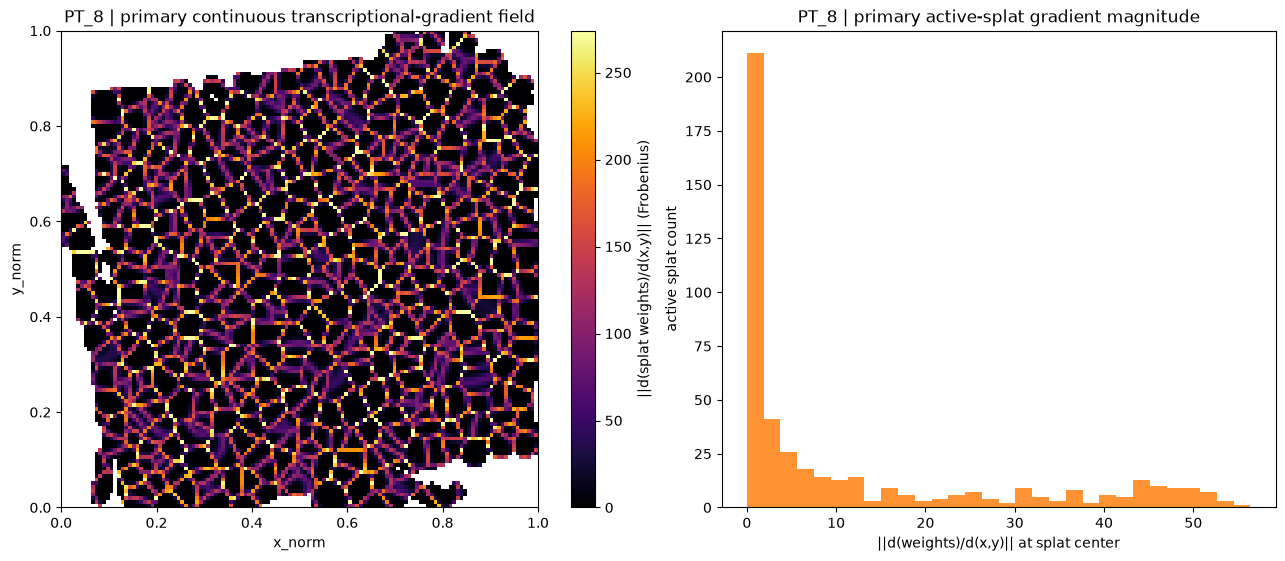

PT_8 | primary transcriptional gradient summary
{'grid_grad_mean': 56.21, 'grid_grad_median': 17.9, 'splat_grad_mean': 11.94, 'splat_grad_median': 2.916}


In [12]:
import torch.func as tfunc

grad_jacobian_chunk_size = 512


def compute_weight_jacobian_norm(model, query_xy: torch.Tensor, *, chunk_size: int = grad_jacobian_chunk_size) -> torch.Tensor:
    """Frobenius norm of the Jacobian of compute_splat_weights w.r.t. query position, at each
    query point -- a marker-free, purely geometric measure of how fast the local mixture of
    underlying programs is changing per unit distance. compute_splat_weights has no dependence
    on the (neural) decoder, only on means/log_scales/rotation/opacity, so this is cheap: no MLP
    forward/backward involved."""
    def weights_fn(xy_point):
        return compute_splat_weights(model, xy_point.unsqueeze(0)).squeeze(0)

    jac_fn = tfunc.vmap(tfunc.jacrev(weights_fn))
    norms = []
    for start in range(0, len(query_xy), chunk_size):
        batch = query_xy[start:start + chunk_size]
        jac = jac_fn(batch)
        norms.append(jac.norm(dim=(1, 2)).detach())
    return torch.cat(norms)


primary_gradient_model = section_splat_results['primary']['model']
primary_active_idx_for_grad = active_splat_indices['primary']
primary_grad_means = primary_gradient_model.means.detach()

primary_tissue_mask_d = section_bundles['primary']['tissue_mask_tensor'].to(device)
with torch.no_grad():
    primary_grid_mask_score = sample_tissue_support(grid_xy, primary_tissue_mask_d).reshape(grid_size, grid_size).cpu().numpy()
    primary_grid_mask_bool = primary_grid_mask_score > grid_mask_threshold

primary_grid_grad_norm = compute_weight_jacobian_norm(primary_gradient_model, grid_xy).cpu().numpy().reshape(grid_size, grid_size)
primary_grid_grad_masked = np.where(primary_grid_mask_bool, primary_grid_grad_norm, np.nan)

# Per-splat gradient magnitude at each active primary splat's own location -- used below to
# cross-reference against transfer scoring.
primary_splat_grad_norm = compute_weight_jacobian_norm(
    primary_gradient_model, primary_grad_means[primary_active_idx_for_grad]
).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
grad_vmax = float(np.nanquantile(primary_grid_grad_masked, 0.98)) if np.isfinite(primary_grid_grad_masked).any() else 1.0
im = axes[0].imshow(primary_grid_grad_masked, origin='lower', extent=[0, 1, 0, 1], cmap='inferno', vmin=0, vmax=grad_vmax)
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label='||d(splat weights)/d(x,y)|| (Frobenius)')
axes[0].set_title(f'{patient_id} | primary continuous transcriptional-gradient field')
axes[0].set_xlabel('x_norm')
axes[0].set_ylabel('y_norm')

axes[1].hist(primary_splat_grad_norm, bins=30, color='tab:orange', alpha=0.85)
axes[1].set_title(f'{patient_id} | primary active-splat gradient magnitude')
axes[1].set_xlabel('||d(weights)/d(x,y)|| at splat center')
axes[1].set_ylabel('active splat count')

export_figure_axes(fig, fallback_prefix='transcriptional_gradient_field')
plt.show()

primary_gradient_summary = {
    'grid_grad_mean': float(np.nanmean(primary_grid_grad_masked)),
    'grid_grad_median': float(np.nanmedian(primary_grid_grad_masked)),
    'splat_grad_mean': float(np.mean(primary_splat_grad_norm)),
    'splat_grad_median': float(np.median(primary_splat_grad_norm)),
}
print(f'{patient_id} | primary transcriptional gradient summary')
print(format_for_display(primary_gradient_summary))

## Does "high gradient" actually mean "invasion-like biology"?

The gradient field (previous section) shows where the tissue's underlying program mixture is
changing fastest -- but a steep gradient could mean a tumor-stroma boundary, a necrotic edge, or an
active invasive front; nothing in its construction distinguishes those. This section checks it
against real biology: an EMT/metastatic-dissemination marker panel curated from an *independent*
PDAC primary/liver-metastasis study (matched snRNA-seq + spatial transcriptomics, Monocle
pseudotime identified a disseminating ductal subpopulation at the tumor boundary with elevated EMT
genes -- PMC12036881, a different dataset and method from the Pei et al. classical/basal markers
used elsewhere in this notebook). If gradient magnitude correlates with this EMT/dissemination
score, that's evidence the gradient field is picking up real invasion-associated biology, not just
generic tissue heterogeneity.

PT_8 | gradient magnitude vs. EMT/dissemination marker score (primary, per-splat)
{'n_emt_markers_available': 15, 'n_emt_markers_total': 15, 'spearman_rho': -0.09105, 'spearman_p': 0.04828, 'n_splats': 471}


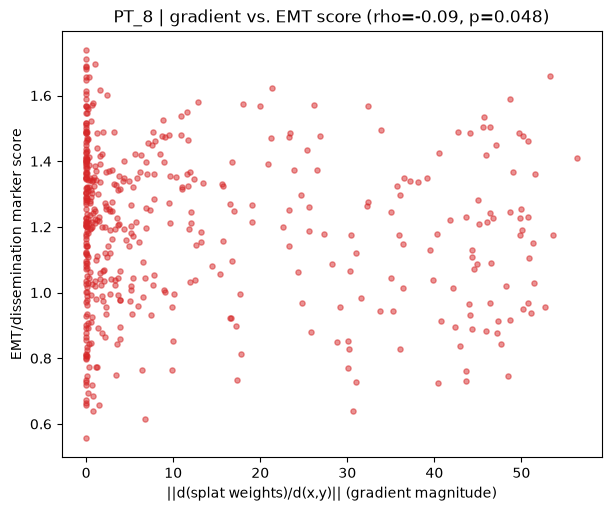

In [13]:
from scipy import stats as scipy_stats
from paper.data_loaders.pdac_mets_visium_pei import load_emt_dissemination_markers

emt_genes = load_emt_dissemination_markers()
primary_gene_names_for_emt = section_bundles['primary']['gene_names']
avail_emt = [g for g in emt_genes if g in primary_gene_names_for_emt]

with torch.no_grad():
    primary_splat_rates_np = primary_gradient_model.splat_rates().detach().cpu().numpy().astype(np.float32)

emt_adata = ad.AnnData(X=primary_splat_rates_np[primary_active_idx_for_grad])
emt_adata.var_names = pd.Index(primary_gene_names_for_emt, dtype=str)
emt_adata.var_names_make_unique()
sc.pp.normalize_total(emt_adata, target_sum=1e4)
sc.pp.log1p(emt_adata)
sc.tl.score_genes(emt_adata, avail_emt, score_name='emt_score', random_state=0)
primary_splat_emt_score = emt_adata.obs['emt_score'].to_numpy()

emt_gradient_rho, emt_gradient_p = scipy_stats.spearmanr(primary_splat_grad_norm, primary_splat_emt_score)
emt_gradient_check = {
    'n_emt_markers_available': len(avail_emt),
    'n_emt_markers_total': len(emt_genes),
    'spearman_rho': float(emt_gradient_rho),
    'spearman_p': float(emt_gradient_p),
    'n_splats': int(len(primary_splat_grad_norm)),
}
print(f'{patient_id} | gradient magnitude vs. EMT/dissemination marker score (primary, per-splat)')
print(format_for_display(emt_gradient_check))

fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
ax.scatter(primary_splat_grad_norm, primary_splat_emt_score, s=14, alpha=0.5, color='tab:red')
ax.set_xlabel('||d(splat weights)/d(x,y)|| (gradient magnitude)')
ax.set_ylabel('EMT/dissemination marker score')
ax.set_title(f'{patient_id} | gradient vs. EMT score (rho={emt_gradient_rho:.2f}, p={emt_gradient_p:.3f})')
export_figure_axes(fig, fallback_prefix='gradient_vs_emt')
plt.show()

## Gradient and EMT score vs. REAL pathologist tumor purity

The check the Pei-cohort version of this notebook could not do: for each active primary splat,
compute the fraction of its *actually covered real spots* (ellipse-containment, same
`coverage_mask_for_points` logic already used in
`family_transfer_multi_patient-pdac_mets_visium-pancreatic_cancer.ipynb`) that carry the
pathologist's own `Tumor Epithelial cells` label -- real ground truth, not an internal-consistency
proxy. Correlate that against both the gradient magnitude and the EMT/dissemination score computed
above. If gradient/EMT are picking up real tumor-associated biology, both should show a real
relationship with actual tumor purity; if not, that's informative in the other direction too.

PT_8 | gradient / EMT score vs. real pathologist tumor purity
{'n_splats_with_covered_spots': 453, 'n_active_splats': 471, 'gradient_vs_real_tumor_purity': {'spearman_rho': 0.06664, 'spearman_p': 0.1568}, 'emt_score_vs_real_tumor_purity': {'spearman_rho': -0.2475, 'spearman_p': 9.439e-08}}


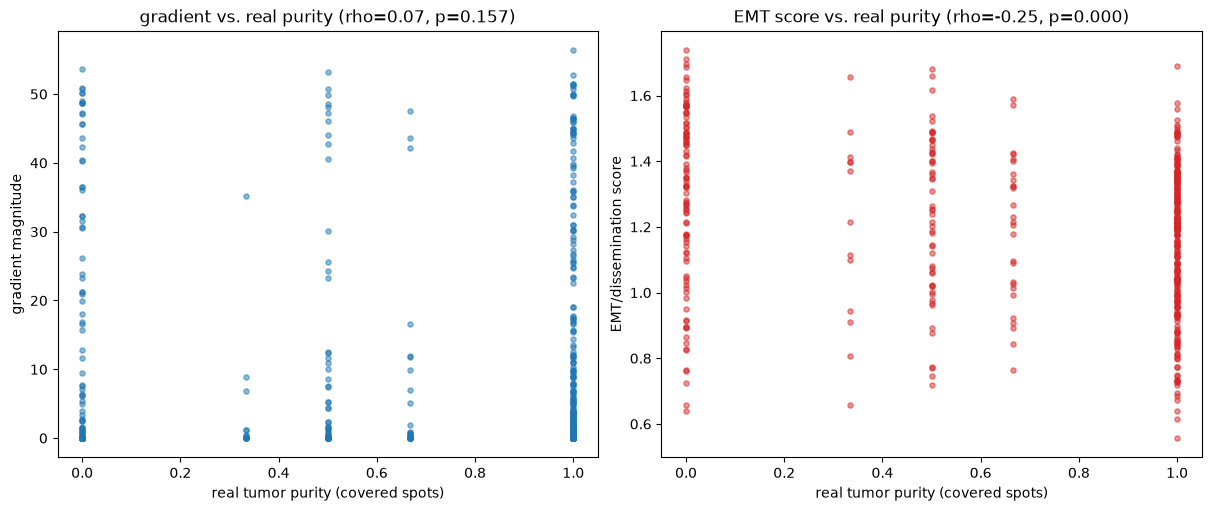

In [14]:
def coverage_mask_for_points(model, points: torch.Tensor, ellipse_threshold: float = 1.0) -> torch.Tensor:
    points = points.to(model.means.device)
    means = model.means
    scales = torch.exp(model.log_scales).clamp_min(1e-8)
    theta = model.rotation.squeeze(-1)

    dx = points[:, None, 0] - means[None, :, 0]
    dy = points[:, None, 1] - means[None, :, 1]
    cos_t = torch.cos(theta)[None, :]
    sin_t = torch.sin(theta)[None, :]
    x_local = cos_t * dx + sin_t * dy
    y_local = -sin_t * dx + cos_t * dy
    norm_sq = (x_local / scales[None, :, 0]) ** 2 + (y_local / scales[None, :, 1]) ** 2
    return norm_sq <= float(ellipse_threshold ** 2)


primary_bundle_for_purity = section_bundles['primary']
with torch.no_grad():
    primary_coverage_mask = coverage_mask_for_points(
        primary_gradient_model, primary_bundle_for_purity['xy_norm'].to(device)
    ).detach().cpu().numpy()

primary_tumor_first_mask = primary_bundle_for_purity['tumor_first_mask']
covered_spot_count = primary_coverage_mask.sum(axis=0)
covered_tumor_purity = np.full(primary_gradient_model.num_splats, np.nan, dtype=np.float64)
for splat_idx in np.flatnonzero(covered_spot_count > 0):
    covered = primary_coverage_mask[:, splat_idx]
    covered_tumor_purity[splat_idx] = float(primary_tumor_first_mask[covered].mean())

active_purity = covered_tumor_purity[primary_active_idx_for_grad]
valid_purity_mask = np.isfinite(active_purity)

purity_grad_rho, purity_grad_p = scipy_stats.spearmanr(
    primary_splat_grad_norm[valid_purity_mask], active_purity[valid_purity_mask]
)
purity_emt_rho, purity_emt_p = scipy_stats.spearmanr(
    primary_splat_emt_score[valid_purity_mask], active_purity[valid_purity_mask]
)

ground_truth_check = {
    'n_splats_with_covered_spots': int(valid_purity_mask.sum()),
    'n_active_splats': int(len(primary_active_idx_for_grad)),
    'gradient_vs_real_tumor_purity': {'spearman_rho': float(purity_grad_rho), 'spearman_p': float(purity_grad_p)},
    'emt_score_vs_real_tumor_purity': {'spearman_rho': float(purity_emt_rho), 'spearman_p': float(purity_emt_p)},
}
print(f'{patient_id} | gradient / EMT score vs. real pathologist tumor purity')
print(format_for_display(ground_truth_check))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].scatter(active_purity[valid_purity_mask], primary_splat_grad_norm[valid_purity_mask], s=14, alpha=0.5, color='tab:blue')
axes[0].set_xlabel('real tumor purity (covered spots)')
axes[0].set_ylabel('gradient magnitude')
axes[0].set_title(f'gradient vs. real purity (rho={purity_grad_rho:.2f}, p={purity_grad_p:.3f})')

axes[1].scatter(active_purity[valid_purity_mask], primary_splat_emt_score[valid_purity_mask], s=14, alpha=0.5, color='tab:red')
axes[1].set_xlabel('real tumor purity (covered spots)')
axes[1].set_ylabel('EMT/dissemination score')
axes[1].set_title(f'EMT score vs. real purity (rho={purity_emt_rho:.2f}, p={purity_emt_p:.3f})')

export_figure_axes(fig, fallback_prefix='gradient_emt_vs_real_purity')
plt.show()

## Tumor-edge zonation: distance-to-boundary via an independent malignant-epithelial vs. stromal/immune marker panel

Rather than correlating the raw pointwise transcriptional-gradient magnitude against tumor
purity globally (see above), this follows the more standard "tumor core vs. invasive edge"
literature design: call each active primary splat tumor-like or non-tumor-like from a marker
panel that is independent of both papers' own transcriptional-subtype framework (not
classical/basal, not the EMT/dissemination panel), then test whether gradient magnitude and
EMT/dissemination score rise specifically as a *tumor* splat gets closer to its own edge -- a
distance computed purely from the splat field's own continuous geometry, not from the real spot
grid.

PT_8 | marker-based tumor call: 249 tumor-like / 222 non-tumor-like active primary splats
PT_8 | tumor-splat distance-to-edge vs. gradient / EMT score (invasion-front test)
{'n_tumor_call': 249, 'n_nontumor_call': 222, 'n_malignant_markers_available': 10, 'n_stromal_markers_available': 12, 'n_zonation_splats': 249, 'distance_to_edge_vs_gradient': {'spearman_rho': -0.3446, 'spearman_p': 2.377e-08}, 'distance_to_edge_vs_emt_score': {'spearman_rho': -0.1588, 'spearman_p': 0.01213}}


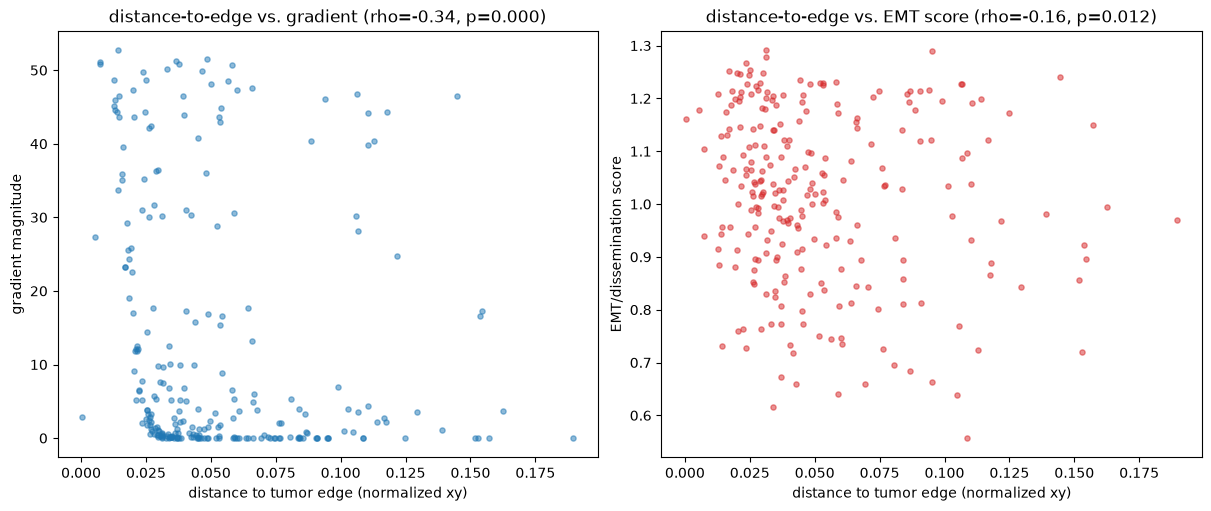

In [15]:
from paper.data_loaders.pdac_mets_visium_pei import load_malignant_epithelial_stromal_markers
from scipy.spatial import cKDTree

malignant_genes, stromal_immune_genes = load_malignant_epithelial_stromal_markers()
primary_gene_names_for_zonation = section_bundles['primary']['gene_names']
avail_malignant = [g for g in malignant_genes if g in primary_gene_names_for_zonation]
avail_stromal = [g for g in stromal_immune_genes if g in primary_gene_names_for_zonation]

zonation_adata = ad.AnnData(X=primary_splat_rates_np[primary_active_idx_for_grad])
zonation_adata.var_names = pd.Index(primary_gene_names_for_zonation, dtype=str)
zonation_adata.var_names_make_unique()
sc.pp.normalize_total(zonation_adata, target_sum=1e4)
sc.pp.log1p(zonation_adata)
sc.tl.score_genes(zonation_adata, avail_malignant, score_name='malignant_score', random_state=0)
sc.tl.score_genes(zonation_adata, avail_stromal, score_name='stromal_score', random_state=0)
primary_malignant_score = zonation_adata.obs['malignant_score'].to_numpy()
primary_stromal_score = zonation_adata.obs['stromal_score'].to_numpy()
primary_tumor_call = primary_malignant_score > primary_stromal_score

n_tumor_call = int(primary_tumor_call.sum())
n_nontumor_call = int((~primary_tumor_call).sum())
print(f'{patient_id} | marker-based tumor call: {n_tumor_call} tumor-like / {n_nontumor_call} non-tumor-like active primary splats')

# Distance-to-edge, restricted to tumor-called splats: distance from each tumor-like splat to
# the nearest non-tumor-like splat -- a "how close is this splat to the tumor's own edge" axis,
# computed purely from splat geometry (no dependence on real spot locations), staying within the
# malignant compartment so the EMT score being tested is measuring the same cell population
# throughout (unlike a signed core-to-stroma axis, which would mix tumor and stromal splats'
# very different baseline EMT-marker expression and confound the test).
primary_zonation_positions = primary_grad_means[primary_active_idx_for_grad].cpu().numpy()
primary_distance_to_edge = np.full(len(primary_zonation_positions), np.nan, dtype=np.float64)
if n_tumor_call > 0 and n_nontumor_call > 0:
    tumor_positions = primary_zonation_positions[primary_tumor_call]
    nontumor_positions = primary_zonation_positions[~primary_tumor_call]
    nontumor_tree = cKDTree(nontumor_positions)
    d_tumor_to_edge, _ = nontumor_tree.query(tumor_positions, k=1)
    primary_distance_to_edge[primary_tumor_call] = d_tumor_to_edge

tumor_call_mask = primary_tumor_call & np.isfinite(primary_distance_to_edge)
n_zonation_splats = int(tumor_call_mask.sum())

if n_zonation_splats >= 10:
    zonation_grad_rho, zonation_grad_p = scipy_stats.spearmanr(
        primary_distance_to_edge[tumor_call_mask], primary_splat_grad_norm[tumor_call_mask]
    )
    zonation_emt_rho, zonation_emt_p = scipy_stats.spearmanr(
        primary_distance_to_edge[tumor_call_mask], primary_splat_emt_score[tumor_call_mask]
    )
    zonation_check = {
        'n_tumor_call': n_tumor_call,
        'n_nontumor_call': n_nontumor_call,
        'n_malignant_markers_available': len(avail_malignant),
        'n_stromal_markers_available': len(avail_stromal),
        'n_zonation_splats': n_zonation_splats,
        'distance_to_edge_vs_gradient': {'spearman_rho': float(zonation_grad_rho), 'spearman_p': float(zonation_grad_p)},
        'distance_to_edge_vs_emt_score': {'spearman_rho': float(zonation_emt_rho), 'spearman_p': float(zonation_emt_p)},
    }
else:
    zonation_grad_rho = zonation_grad_p = zonation_emt_rho = zonation_emt_p = float('nan')
    zonation_check = {
        'n_tumor_call': n_tumor_call,
        'n_nontumor_call': n_nontumor_call,
        'skipped': True,
        'reason': f'too few tumor-called splats with a computable edge distance (n={n_zonation_splats})',
    }
print(f'{patient_id} | tumor-splat distance-to-edge vs. gradient / EMT score (invasion-front test)')
print(format_for_display(zonation_check))

if n_zonation_splats >= 10:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    axes[0].scatter(primary_distance_to_edge[tumor_call_mask], primary_splat_grad_norm[tumor_call_mask], s=14, alpha=0.5, color='tab:blue')
    axes[0].set_xlabel('distance to tumor edge (normalized xy)')
    axes[0].set_ylabel('gradient magnitude')
    axes[0].set_title(f'distance-to-edge vs. gradient (rho={zonation_grad_rho:.2f}, p={zonation_grad_p:.3f})')

    axes[1].scatter(primary_distance_to_edge[tumor_call_mask], primary_splat_emt_score[tumor_call_mask], s=14, alpha=0.5, color='tab:red')
    axes[1].set_xlabel('distance to tumor edge (normalized xy)')
    axes[1].set_ylabel('EMT/dissemination score')
    axes[1].set_title(f'distance-to-edge vs. EMT score (rho={zonation_emt_rho:.2f}, p={zonation_emt_p:.3f})')

    export_figure_axes(fig, fallback_prefix='zonation_distance_to_edge')
    plt.show()

### Marker-based tumor call vs. REAL pathologist tumor label (Khaliq-only sanity check)

Khaliq et al. spots carry a real cell-type-deconvolution label (`first_type`), already used
above for `covered_tumor_purity`. That lets us check whether the marker panel's tumor/non-tumor
call for each splat actually agrees with real ground truth, rather than trusting it blindly --
something the Pei cohort (no per-spot annotation) can't do.

In [16]:
from sklearn.metrics import roc_auc_score

active_covered_purity = covered_tumor_purity[primary_active_idx_for_grad]
valid_val_mask = np.isfinite(active_covered_purity)
real_tumor_binary = active_covered_purity[valid_val_mask] > 0.5
marker_tumor_binary = primary_tumor_call[valid_val_mask]

zonation_marker_validation = {
    'n_splats_validated': int(valid_val_mask.sum()),
    'accuracy_vs_real_tumor_label': float((real_tumor_binary == marker_tumor_binary).mean()),
    'auroc_malignant_score_vs_real_tumor_label': (
        float(roc_auc_score(real_tumor_binary, primary_malignant_score[valid_val_mask]))
        if len(set(real_tumor_binary)) > 1 else float('nan')
    ),
}
print(f'{patient_id} | marker-based tumor call vs. REAL pathologist tumor label (validation)')
print(format_for_display(zonation_marker_validation))

PT_8 | marker-based tumor call vs. REAL pathologist tumor label (validation)
{'n_splats_validated': 453, 'accuracy_vs_real_tumor_label': 0.6203, 'auroc_malignant_score_vs_real_tumor_label': 0.678}


## Primary program families

Group active primary splats by decoded-composition cosine similarity into recurring program
families -- entirely unsupervised (no annotations used or available for this cohort), exactly the
method already used on the Khaliq cohort. Each family gets a prototype (mean normalized composition
of its members) used for transfer scoring below.

PT_8 | primary program family summary
{'n_active_primary_splats': 471, 'n_primary_program_families_total': 29, 'n_primary_program_families_retained': 21, 'family_cosine_threshold': 0.95, 'largest_retained_family_size': 106, 'median_retained_family_size': 10.0}
PT_8 | retained families (top 8)
{'family_0': {'family_id': 1, 'size': 106, 'representative_splat_index': 1, 'median_mean_usage': 0.002162, 'median_peak_usage': 0.9993, 'median_plasticity_score': -0.4026, 'top_genes': ['IGKC', 'UBC', 'S100A6', 'FTL', 'TMSB4X', 'OLFM4', 'ACTB', 'LYZ', 'IGHA1', 'B2M']}, 'family_1': {'family_id': 2, 'size': 100, 'representative_splat_index': 2, 'median_mean_usage': 0.00188, 'median_peak_usage': 0.9994, 'median_plasticity_score': -0.5577, 'top_genes': ['S100A6', 'OLFM4', 'UBC', 'TMSB4X', 'LYZ', 'FTL', 'SPINK1', 'ACTB', 'IGKC', 'B2M']}, 'family_2': {'family_id': 3, 'size': 53, 'representative_splat_index': 3, 'median_mean_usage': 0.001936, 'median_peak_usage': 0.9986, 'median_plasticity_score': 0.0018

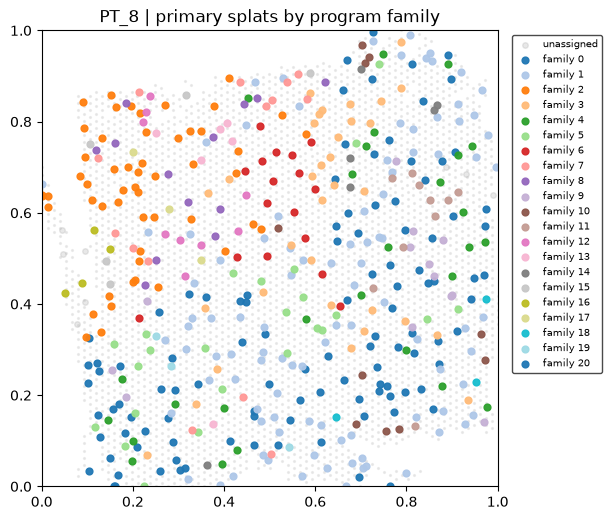

Saved family prototypes for cross-patient check to /home/ns5404/singh_research/spatsplat_project/spatsplat/figures/zonation_metastasis_khaliq/PT_8/cross_patient_artifacts


In [17]:
def top_gene_labels(comp_row: np.ndarray, gene_names: np.ndarray, k: int = 10):
    idx = np.argsort(comp_row)[::-1][:k]
    return [str(gene_names[i]) for i in idx]


primary_bundle = section_bundles['primary']
primary_model = section_splat_results['primary']['model']
primary_gene_names = np.asarray(primary_bundle['gene_names'], dtype=object)
active_primary_idx = active_splat_indices['primary']

with torch.no_grad():
    primary_composition = primary_model.splat_composition().detach().cpu()
    primary_weights = compute_splat_weights(primary_model, primary_bundle['xy_norm'].to(device)).detach().cpu().numpy()
primary_mean_usage = primary_weights.mean(axis=0)
primary_peak_usage = primary_weights.max(axis=0)

active_primary_comp = primary_composition[active_primary_idx]
active_primary_comp = active_primary_comp / active_primary_comp.norm(dim=1, keepdim=True).clamp_min(1e-8)
primary_pairwise_cosine = (active_primary_comp @ active_primary_comp.T).numpy()

remaining = list(range(len(active_primary_idx)))
primary_program_families = []
while remaining:
    seed_local_idx = remaining[0]
    seed_sim = primary_pairwise_cosine[seed_local_idx]
    family_local = [idx for idx in remaining if seed_sim[idx] >= primary_family_cosine_threshold]
    primary_program_families.append(family_local)
    remaining = [idx for idx in remaining if idx not in family_local]

all_family_records = []
active_primary_family_ids = np.full(len(active_primary_idx), -1, dtype=np.int64)
for family_id, family_local in enumerate(primary_program_families):
    for local_idx in family_local:
        active_primary_family_ids[local_idx] = family_id

    family_splat_idx = active_primary_idx[family_local]
    family_comp = primary_composition[family_splat_idx].mean(dim=0).numpy()
    family_gene_labels = top_gene_labels(family_comp, primary_gene_names, k=10)
    family_plasticity = section_lineage_dfs['primary'].set_index('splat_idx').loc[family_splat_idx, 'plasticity_score']

    all_family_records.append({
        'family_id': int(family_id),
        'size': int(len(family_local)),
        'representative_splat_index': int(family_splat_idx[0]),
        'median_mean_usage': float(np.median(primary_mean_usage[family_splat_idx])),
        'median_peak_usage': float(np.median(primary_peak_usage[family_splat_idx])),
        'median_plasticity_score': float(family_plasticity.median()),
        'top_genes': family_gene_labels,
    })

all_family_records = sorted(all_family_records, key=lambda rec: (-rec['size'], -rec['median_mean_usage']))
family_records = [rec for rec in all_family_records if rec['size'] >= primary_family_min_size]
if not family_records:
    family_records = all_family_records[:min(max_primary_families_report, len(all_family_records))]

family_rank_map = {rec['family_id']: rank for rank, rec in enumerate(family_records)}
ordered_family_ids = np.array([family_rank_map.get(fid, -1) for fid in active_primary_family_ids], dtype=np.int64)

primary_program_family_summary = {
    'n_active_primary_splats': int(len(active_primary_idx)),
    'n_primary_program_families_total': int(len(all_family_records)),
    'n_primary_program_families_retained': int(len(family_records)),
    'family_cosine_threshold': float(primary_family_cosine_threshold),
    'largest_retained_family_size': int(max((rec['size'] for rec in family_records), default=0)),
    'median_retained_family_size': float(np.median([rec['size'] for rec in family_records])) if family_records else float('nan'),
}
print(f'{patient_id} | primary program family summary')
print(format_for_display(primary_program_family_summary))
print(f'{patient_id} | retained families (top {max_primary_families_report})')
print(format_for_display({f'family_{rank}': rec for rank, rec in enumerate(family_records[:max_primary_families_report])}))

family_prototypes = []
for rec in family_records:
    family_local = np.flatnonzero(active_primary_family_ids == rec['family_id'])
    family_splat_idx = active_primary_idx[family_local]
    proto = primary_composition[family_splat_idx].mean(dim=0)
    proto = proto / proto.norm().clamp_min(1e-8)
    family_prototypes.append(proto)
family_prototypes = torch.stack(family_prototypes, dim=0) if family_prototypes else torch.empty(0, primary_composition.shape[1])

shared_family_palette = list(plt.get_cmap('tab20').colors)
family_rank_to_color = {rank: shared_family_palette[rank % len(shared_family_palette)] for rank in range(len(family_records))}
family_rank_to_color.setdefault(-1, (0.7, 0.7, 0.7, 1.0))

fig, ax = plt.subplots(figsize=(6, 5.5), constrained_layout=True)
primary_means_np = primary_model.means.detach().cpu().numpy()
primary_xy_norm_np = primary_bundle['xy_norm'].numpy()
ax.scatter(primary_xy_norm_np[:, 0], primary_xy_norm_np[:, 1], s=2, alpha=0.06, color='black')
selected_means_np = primary_means_np[active_primary_idx]
unassigned_mask = ordered_family_ids == -1
if np.any(unassigned_mask):
    ax.scatter(selected_means_np[unassigned_mask, 0], selected_means_np[unassigned_mask, 1], s=16, alpha=0.3, color=family_rank_to_color[-1], label='unassigned')
for family_rank, rec in enumerate(family_records):
    mask = ordered_family_ids == family_rank
    if np.any(mask):
        ax.scatter(selected_means_np[mask, 0], selected_means_np[mask, 1], s=24, alpha=0.95, color=family_rank_to_color[family_rank], label=f'family {family_rank}')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')
ax.set_title(f'{patient_id} | primary splats by program family')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=7)
export_figure_axes(fig, fallback_prefix='primary_program_families')
plt.show()

# Saved for a cross-patient negative control (run separately, CPU-only, after every patient has
# been processed): is a met splat's best match to ITS OWN patient's primary families reliably
# better than its match to a DIFFERENT patient's primary families? If not, "transfer" is picking
# up something generic (shared malignant-epithelial identity) rather than real patient-specific
# correspondence.
cross_patient_dir = FIGURE_EXPORT_DIR / 'cross_patient_artifacts'
cross_patient_dir.mkdir(parents=True, exist_ok=True)
np.save(cross_patient_dir / 'family_prototypes.npy', family_prototypes.detach().cpu().numpy().astype(np.float32))
with open(cross_patient_dir / 'gene_names.json', 'w') as f:
    json.dump(list(primary_gene_names), f)
print(f'Saved family prototypes for cross-patient check to {cross_patient_dir}')

## Family spatial coherence (Moran's I)

Sanity-check that each retained family is spatially clustered tissue biology, not scattered noise a cosine threshold happened to group together -- permutation-based p-values (1000 permutations), BH-FDR corrected jointly across every family tested.

In [18]:
family_indicator_cols = {}
for family_rank in range(len(family_records)):
    indicator = (ordered_family_ids == family_rank).astype(np.float32)
    if indicator.std() > 0:
        family_indicator_cols[f'family_{family_rank}'] = indicator

n_active_for_moran = len(active_primary_idx)
if n_active_for_moran < 3 or not family_indicator_cols:
    print('WARNING: too few active splats or no non-degenerate families -- skipping Moran\'s I')
    primary_family_moran_summary = {}
else:
    moran_adata = ad.AnnData(X=np.zeros((n_active_for_moran, 1), dtype=np.float32))
    moran_adata.obsm['spatial'] = primary_means_np[active_primary_idx]
    for col_name, indicator in family_indicator_cols.items():
        moran_adata.obs[col_name] = indicator

    sq.gr.spatial_neighbors_knn(moran_adata, n_neighs=min(6, n_active_for_moran - 1))
    moran_result = sq.gr.spatial_autocorr(
        moran_adata, mode='moran', attr='obs', genes=list(family_indicator_cols.keys()),
        n_perms=1000, seed=random_seed, corr_method='fdr_bh', copy=True, show_progress_bar=False,
    )
    primary_family_moran_summary = {
        col_name: {
            'moran_i': float(moran_result.loc[col_name, 'I']),
            'pval_sim_fdr_bh': float(moran_result.loc[col_name, 'pval_sim_fdr_bh']),
            'n_active_splats_in_family': int(family_indicator_cols[col_name].sum()),
        }
        for col_name in family_indicator_cols
    }

print(f"{patient_id} | primary program family spatial coherence (Moran's I, BH-FDR corrected)")
print(format_for_display(primary_family_moran_summary))

INFO     Creating graph using `None` transform and `1` libraries.                                                  


PT_8 | primary program family spatial coherence (Moran's I, BH-FDR corrected)
{'family_0': {'moran_i': 0.1867, 'pval_sim_fdr_bh': 0.002331, 'n_active_splats_in_family': 106}, 'family_1': {'moran_i': 0.198, 'pval_sim_fdr_bh': 0.002331, 'n_active_splats_in_family': 100}, 'family_2': {'moran_i': 0.4173, 'pval_sim_fdr_bh': 0.002331, 'n_active_splats_in_family': 53}, 'family_3': {'moran_i': 0.1617, 'pval_sim_fdr_bh': 0.002331, 'n_active_splats_in_family': 33}, 'family_4': {'moran_i': 0.01101, 'pval_sim_fdr_bh': 0.3754, 'n_active_splats_in_family': 27}, 'family_5': {'moran_i': 0.05099, 'pval_sim_fdr_bh': 0.01648, 'n_active_splats_in_family': 24}, 'family_6': {'moran_i': 0.2935, 'pval_sim_fdr_bh': 0.002331, 'n_active_splats_in_family': 17}, 'family_7': {'moran_i': 0.1133, 'pval_sim_fdr_bh': 0.002331, 'n_active_splats_in_family': 14}, 'family_8': {'moran_i': 0.07382, 'pval_sim_fdr_bh': 0.008069, 'n_active_splats_in_family': 13}, 'family_9': {'moran_i': 0.1273, 'pval_sim_fdr_bh': 0.002331, 'n_a

## Cross-section transfer scoring

For each metastatic section, score every active splat against every primary family prototype
(cosine similarity of decoded composition), then characterize how *distinctively* each splat
matches its best family -- **as a continuous statistic, not a significant/not-significant gate**.

Two attempts at an absolute-threshold significance test both failed, in complementary directions:
a fixed 0.9-cosine gate (copied from the Khaliq-cohort pipeline) certified zero transfer-supported
families despite decent-looking scores (0.73-0.87 median) -- too strict. A gene-label-shuffled
permutation null was trivially beaten by any coherent profile -- 100% "significant" everywhere, no
discrimination -- too weak. A real-data null built from primary splats' cosine to families they
don't belong to then swung back to 0% "significant" everywhere, apparently as strict as the real
scores themselves, likely inflated by near-duplicate neighboring families sitting just below the
0.95 family-clustering cutoff. All three failures point to the same underlying fact: raw
whole-transcriptome cosine similarity between *any* two real profiles in this tissue lives in a
narrow, compressed high range, making any absolute-cutoff test on it fragile.

The fix: a **self-referential, per-splat z-score** that needs no external population at all --
`z = (best_family_score - mean(other_10_family_scores)) / std(other_10_family_scores)`. This asks
"how distinctly does this splat pick one family over its own full repertoire of comparisons,"
never comparing against anything outside that splat's own row of scores, so it can't inherit either
failure mode above. Reported continuously per splat and aggregated (median) per family -- no
binary "transfer-supported" classification anymore. Still entirely unsupervised -- **no pathologist
labels involved at any point**, this cohort doesn't have any.

Each family's matched splats also get their own `plasticity_score` reported as a diagnostic, and
the whole result is cross-checked against Table S6's published per-section
classical/intermediate/basal percentages in a later section.

In [19]:
def score_transfer(role):
    bundle = section_bundles[role]
    model = section_splat_results[role]['model']
    active_idx = active_splat_indices[role]
    lineage_df = section_lineage_dfs[role].set_index('splat_idx')

    with torch.no_grad():
        composition = model.splat_composition().detach().cpu()
        comp_norm = composition / composition.norm(dim=1, keepdim=True).clamp_min(1e-8)
        comp_active = comp_norm[active_idx]
        family_cosine = comp_active @ family_prototypes.T

    cross_patient_dir = FIGURE_EXPORT_DIR / 'cross_patient_artifacts'
    cross_patient_dir.mkdir(parents=True, exist_ok=True)
    np.save(cross_patient_dir / f'{role}_met_composition_fp16.npy', comp_active.numpy().astype(np.float16))

    n_families = family_cosine.shape[1]
    if n_families < 2:
        return None

    scores_np = family_cosine.numpy()
    best_rank = scores_np.argmax(axis=1)
    best_score = scores_np[np.arange(len(scores_np)), best_rank]

    # Self-referential distinctiveness: exclude each splat's own best-family score and ask how
    # many standard deviations it sits above the mean of that SAME splat's scores to every other
    # family -- no external population, so it can't inherit either failure mode described above.
    total_sum = scores_np.sum(axis=1)
    total_sumsq = (scores_np ** 2).sum(axis=1)
    other_sum = total_sum - best_score
    other_sumsq = total_sumsq - best_score ** 2
    n_other = n_families - 1
    other_mean = other_sum / n_other
    other_var = np.clip(other_sumsq / n_other - other_mean ** 2, 1e-12, None)
    other_std = np.sqrt(other_var)
    z_score = (best_score - other_mean) / np.clip(other_std, 1e-6, None)

    second_best = np.partition(scores_np, -2, axis=1)[:, -2]
    assignment_margin = best_score - second_best

    family_role_records = []
    for family_rank, rec in enumerate(family_records):
        splat_mask = best_rank == family_rank
        matched_splats = int(splat_mask.sum())
        median_score = float(np.median(best_score[splat_mask])) if matched_splats > 0 else float('nan')
        median_margin = float(np.median(assignment_margin[splat_mask])) if matched_splats > 0 else float('nan')
        median_z = float(np.median(z_score[splat_mask])) if matched_splats > 0 else float('nan')
        matched_splat_idx = active_idx[splat_mask]
        median_matched_plasticity = float(lineage_df.loc[matched_splat_idx, 'plasticity_score'].median()) if matched_splats > 0 else float('nan')

        ig_top_gene_fraction = float(np.mean([
            str(g).upper().startswith(ig_gene_prefixes) for g in rec['top_genes'][:ig_topk]
        ])) if rec['top_genes'] else 0.0
        is_ig_dominant = ig_top_gene_fraction >= ig_top_gene_fraction_threshold

        family_role_records.append({
            'family_rank': int(family_rank),
            'primary_family_id': int(rec['family_id']),
            'matched_splats': matched_splats,
            'median_match_score': median_score,
            'median_assignment_margin': median_margin,
            'median_z_score': median_z,
            'median_matched_plasticity_score': median_matched_plasticity,
            'primary_family_median_plasticity_score': rec['median_plasticity_score'],
            'is_ig_dominant': bool(is_ig_dominant),
            'top_genes': rec['top_genes'],
        })

    return {
        'role': role,
        'best_score': best_score,
        'best_rank': best_rank,
        'assignment_margin': assignment_margin,
        'z_score': z_score,
        'family_role_records': family_role_records,
        'summary': {
            'n_active_splats': int(len(active_idx)),
            'median_best_family_score': float(np.median(best_score)),
            'median_assignment_margin': float(np.median(assignment_margin)),
            'median_z_score': float(np.median(z_score)),
            'n_families_tested': len(family_records),
        },
    }


transfer_results = {role: score_transfer(role) for role in met_roles}

transfer_summary = {role: result['summary'] for role, result in transfer_results.items() if result is not None}
print(f'{patient_id} | transfer scoring summary by metastatic section')
print(format_for_display(transfer_summary))

PT_8 | transfer scoring summary by metastatic section
{'liver_sample': {'n_active_splats': 503, 'median_best_family_score': 0.187, 'median_assignment_margin': 0.001103, 'median_z_score': 1.129, 'n_families_tested': 21}, 'lymph_node_met': {'n_active_splats': 424, 'median_best_family_score': 0.9533, 'median_assignment_margin': 0.01699, 'median_z_score': 1.96, 'n_families_tested': 21}}


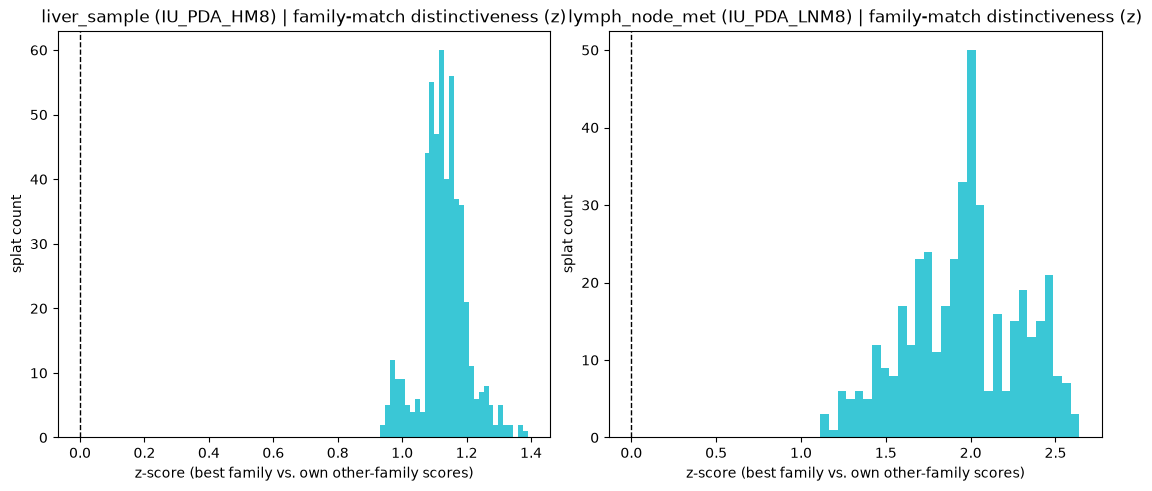

PT_8 | per-family transfer distinctiveness by section (top 8 families by size)

--- liver_sample ---
[{'family_rank': 17, 'primary_family_id': 22, 'matched_splats': 215, 'median_match_score': 0.1864, 'median_assignment_margin': 0.001131, 'median_z_score': 1.129, 'median_matched_plasticity_score': -0.02432, 'primary_family_median_plasticity_score': 0.05996, 'is_ig_dominant': False, 'top_genes': ['UBC', 'FTL', 'FN1', 'S100A6', 'ACTB', 'TMSB4X', 'FTH1', 'OLFM4', 'MT2A', 'B2M']}, {'family_rank': 8, 'primary_family_id': 11, 'matched_splats': 119, 'median_match_score': 0.1341, 'median_assignment_margin': 0.0007559, 'median_z_score': 1.189, 'median_matched_plasticity_score': -0.02692, 'primary_family_median_plasticity_score': 0.08068, 'is_ig_dominant': False, 'top_genes': ['UBC', 'FN1', 'ACTB', 'OLFM4', 'S100A6', 'FTL', 'TMSB4X', 'IGKC', 'SPARC', 'FTH1']}, {'family_rank': 3, 'primary_family_id': 7, 'matched_splats': 87, 'median_match_score': 0.2962, 'median_assignment_margin': 0.002915, 'medi

In [20]:
fig, axes = plt.subplots(1, len(met_roles), figsize=(5.5 * len(met_roles), 4.8), constrained_layout=True, squeeze=False)
for col, role in enumerate(met_roles):
    result = transfer_results[role]
    ax = axes[0][col]
    if result is None:
        ax.set_title(f'{role} | no primary families to score against')
        continue
    ax.hist(result['z_score'], bins=30, color='tab:cyan', alpha=0.85)
    ax.axvline(0.0, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'{role} ({section_bundles[role]["sample_title"]}) | family-match distinctiveness (z)')
    ax.set_xlabel('z-score (best family vs. own other-family scores)')
    ax.set_ylabel('splat count')
export_figure_axes(fig, fallback_prefix='transfer_distinctiveness_distributions')
plt.show()

print(f'{patient_id} | per-family transfer distinctiveness by section (top {max_primary_families_report} families by size)')
for role in met_roles:
    result = transfer_results[role]
    if result is None:
        continue
    records_sorted = sorted(result['family_role_records'], key=lambda r: -r['matched_splats'])
    print(f'\n--- {role} ---')
    print(format_for_display(records_sorted[:max_primary_families_report]))

## Gradient magnitude vs. transfer distinctiveness, and a plasticity alternative

The actual question motivating the gradient field: do primary families sitting in high-gradient
transition zones transfer more *distinctively* into the metastatic sections than families sitting
in low-gradient, stable-program interiors? Two versions of the gradient measurement are tested:

1. **Family median** -- median `primary_splat_grad_norm` over *every* splat in a family, the
   version used in the single-patient pilot.
2. **Boundary-restricted** -- median gradient over only a family's *boundary* splats (splats whose
   nearest neighbors, by position, include at least one different retained family) -- a more
   targeted operationalization of "invasive edge," since a family median can be diluted by splats
   sitting deep in that family's own interior, far from any real transition.

A third, independent hypothesis is tested alongside the gradient ones: does a family's
`plasticity_score` (basal- vs. classical-leaning, from the marker-based scoring earlier) predict
how distinctively it transfers -- directly testing, at cohort scale, whether basal-leaning primary
programs metastasize preferentially, the pattern Pei et al. reported on their own independent
cohort.

All three use the same family-level Spearman correlation against `median_z_score`, restricted to
families with at least `transfer_family_min_matched_splats` matched splats per section.
**Exploratory, not confirmatory** at the single-patient level -- real signal here is only
trustworthy once aggregated across every qualifying patient (see the follow-up comparison
notebook).

In [21]:
from scipy import stats as scipy_stats
from scipy.spatial import cKDTree

# Boundary-restricted gradient: for each active primary splat, check whether any of its k
# nearest OTHER active primary splats (by position) belong to a different retained family -- a
# "boundary" splat sits spatially adjacent to at least one different program, a more targeted
# stand-in for "invasive edge" than a family's full membership (much of which can sit deep in
# that family's own interior).
boundary_k = 6
primary_positions_for_knn = primary_means_np[active_primary_idx]
n_active_primary_for_knn = len(active_primary_idx)
is_boundary_splat = np.zeros(n_active_primary_for_knn, dtype=bool)
if n_active_primary_for_knn > boundary_k:
    tree = cKDTree(primary_positions_for_knn)
    _, neighbor_idx = tree.query(primary_positions_for_knn, k=boundary_k + 1)  # col 0 is self
    for i in range(n_active_primary_for_knn):
        own_family = ordered_family_ids[i]
        if own_family == -1:
            continue
        neighbor_families = ordered_family_ids[neighbor_idx[i, 1:]]
        if np.any((neighbor_families != own_family) & (neighbor_families != -1)):
            is_boundary_splat[i] = True

print(f'{patient_id} | boundary splats: {int(is_boundary_splat.sum())}/{n_active_primary_for_knn}')

family_primary_grad_median = {}
family_primary_grad_median_boundary = {}
for family_rank in range(len(family_records)):
    member_mask = ordered_family_ids == family_rank
    family_primary_grad_median[family_rank] = (
        float(np.median(primary_splat_grad_norm[member_mask])) if np.any(member_mask) else float('nan')
    )
    boundary_member_mask = member_mask & is_boundary_splat
    family_primary_grad_median_boundary[family_rank] = (
        float(np.median(primary_splat_grad_norm[boundary_member_mask]))
        if np.any(boundary_member_mask)
        else family_primary_grad_median[family_rank]
    )


def spearman_family_link(x_fn, *, y_key='median_z_score', min_matched=transfer_family_min_matched_splats):
    results = {}
    for role in met_roles:
        result = transfer_results[role]
        if result is None:
            results[role] = {'skipped': True, 'reason': 'no primary families to score against'}
            continue
        xs, ys = [], []
        for rec in result['family_role_records']:
            if rec['matched_splats'] < min_matched:
                continue
            x = x_fn(rec)
            y = rec[y_key]
            if x is None or not np.isfinite(x) or not np.isfinite(y):
                continue
            xs.append(x)
            ys.append(y)
        if len(xs) < 4:
            results[role] = {'skipped': True, 'reason': f'too few families with >={min_matched} matched splats (n={len(xs)})'}
            continue
        rho, p_value = scipy_stats.spearmanr(xs, ys)
        results[role] = {'n_families': len(xs), 'spearman_rho': float(rho), 'spearman_p': float(p_value)}
    return results


gradient_transfer_link = spearman_family_link(lambda rec: family_primary_grad_median.get(rec['family_rank']))
gradient_transfer_link_boundary = spearman_family_link(lambda rec: family_primary_grad_median_boundary.get(rec['family_rank']))
plasticity_transfer_link = spearman_family_link(lambda rec: rec['primary_family_median_plasticity_score'])

print(f'{patient_id} | gradient (family median) vs. transfer distinctiveness (Spearman)')
print(format_for_display(gradient_transfer_link))
print(f'\n{patient_id} | gradient (boundary-restricted) vs. transfer distinctiveness (Spearman)')
print(format_for_display(gradient_transfer_link_boundary))
print(f'\n{patient_id} | plasticity score vs. transfer distinctiveness (Spearman)')
print(format_for_display(plasticity_transfer_link))

PT_8 | boundary splats: 455/471
PT_8 | gradient (family median) vs. transfer distinctiveness (Spearman)
{'liver_sample': {'n_families': 5, 'spearman_rho': 0.6, 'spearman_p': 0.2848}, 'lymph_node_met': {'n_families': 7, 'spearman_rho': 0.75, 'spearman_p': 0.05218}}

PT_8 | gradient (boundary-restricted) vs. transfer distinctiveness (Spearman)
{'liver_sample': {'n_families': 5, 'spearman_rho': 0.6, 'spearman_p': 0.2848}, 'lymph_node_met': {'n_families': 7, 'spearman_rho': 0.75, 'spearman_p': 0.05218}}

PT_8 | plasticity score vs. transfer distinctiveness (Spearman)
{'liver_sample': {'n_families': 5, 'spearman_rho': 0.9, 'spearman_p': 0.03739}, 'lymph_node_met': {'n_families': 7, 'spearman_rho': 0.2143, 'spearman_p': 0.6445}}


## Primary program families vs. real tumor purity

No Table S6 equivalent exists for this cohort (that was a Pei et al.-specific published percentage
table) -- the equivalent, stronger check here: does each retained primary program family's real
pathologist tumor purity (median over its member splats' covered-spot purity, computed above) line
up with the family's own median `plasticity_score`? A family that's genuinely tumor-associated
should show both higher real tumor purity and a clear basal/classical identity, not a diffuse,
low-purity signature.

In [22]:
family_real_purity = {}
for family_rank in range(len(family_records)):
    family_local = np.flatnonzero(ordered_family_ids == family_rank)
    family_splat_idx = active_primary_idx[family_local]
    purities = covered_tumor_purity[family_splat_idx]
    purities = purities[np.isfinite(purities)]
    family_real_purity[family_rank] = float(np.median(purities)) if len(purities) else float('nan')

family_purity_table = []
for family_rank, rec in enumerate(family_records):
    family_purity_table.append({
        'family_rank': family_rank,
        'primary_family_id': rec['family_id'],
        'size': rec['size'],
        'median_real_tumor_purity': family_real_purity.get(family_rank, float('nan')),
        'median_plasticity_score': rec['median_plasticity_score'],
        'top_genes': rec['top_genes'][:5],
    })

print(f'{patient_id} | retained families: real tumor purity vs. plasticity score')
print(format_for_display(family_purity_table))

valid_families = [f for f in family_purity_table if np.isfinite(f['median_real_tumor_purity'])]
if len(valid_families) >= 4:
    purity_plasticity_rho, purity_plasticity_p = scipy_stats.spearmanr(
        [f['median_real_tumor_purity'] for f in valid_families],
        [f['median_plasticity_score'] for f in valid_families],
    )
    family_purity_plasticity_link = {
        'n_families': len(valid_families),
        'spearman_rho': float(purity_plasticity_rho),
        'spearman_p': float(purity_plasticity_p),
    }
else:
    family_purity_plasticity_link = {'skipped': True, 'reason': f'too few families with real purity data (n={len(valid_families)})'}
print(f'\n{patient_id} | family-level real tumor purity vs. plasticity score (Spearman)')
print(format_for_display(family_purity_plasticity_link))

PT_8 | retained families: real tumor purity vs. plasticity score
[{'family_rank': 0, 'primary_family_id': 1, 'size': 106, 'median_real_tumor_purity': 1.0, 'median_plasticity_score': -0.4026, 'top_genes': ['IGKC', 'UBC', 'S100A6', 'FTL', 'TMSB4X']}, {'family_rank': 1, 'primary_family_id': 2, 'size': 100, 'median_real_tumor_purity': 1.0, 'median_plasticity_score': -0.5577, 'top_genes': ['S100A6', 'OLFM4', 'UBC', 'TMSB4X', 'LYZ']}, {'family_rank': 2, 'primary_family_id': 3, 'size': 53, 'median_real_tumor_purity': 1.0, 'median_plasticity_score': 0.001834, 'top_genes': ['UBC', 'S100A6', 'ACTB', 'OLFM4', 'TMSB4X']}, {'family_rank': 3, 'primary_family_id': 7, 'size': 33, 'median_real_tumor_purity': 0.6667, 'median_plasticity_score': -0.183, 'top_genes': ['UBC', 'OLFM4', 'FTL', 'ACTB', 'IGKC']}, {'family_rank': 4, 'primary_family_id': 6, 'size': 27, 'median_real_tumor_purity': 0.5, 'median_plasticity_score': -0.3036, 'top_genes': ['IGKC', 'IGHA1', 'IGHG1', 'UBC', 'TMSB4X']}, {'family_rank': 5,

## Patient summary export

Saves this patient's headline numbers so a follow-up cross-patient comparison can aggregate across
every patient run via `scripts/run_gradient_metastasis_khaliq_notebook.py`.

In [23]:
def _json_safe(obj):
    if isinstance(obj, dict):
        return {str(k): _json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_json_safe(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        v = float(obj)
        return v if np.isfinite(v) else None
    if isinstance(obj, np.ndarray):
        return _json_safe(obj.tolist())
    if isinstance(obj, (bool, int, float, str)) or obj is None:
        return obj
    return str(obj)


primary_gradient_summary['n_boundary_splats'] = int(is_boundary_splat.sum())
primary_gradient_summary['n_active_primary_for_boundary'] = int(n_active_primary_for_knn)

patient_summary = {
    'patient_id': patient_id,
    'patient_sections': patient_sections,
    'met_roles': met_roles,
    'section_summary': section_summary,
    'comparison_test_mae': comparison_df.reset_index().to_dict(orient='records'),
    'splat_utilization_summary': splat_utilization_summary,
    'plasticity_by_section': plasticity_by_section.reset_index().to_dict(orient='records'),
    'primary_program_family_summary': primary_program_family_summary,
    'primary_family_moran_summary': primary_family_moran_summary,
    'primary_gradient_summary': primary_gradient_summary,
    'emt_gradient_check': emt_gradient_check,
    'ground_truth_check': ground_truth_check,
    'family_purity_table': family_purity_table,
    'family_purity_plasticity_link': family_purity_plasticity_link,
    'zonation_check': zonation_check,
    'zonation_marker_validation': zonation_marker_validation,
    'transfer_summary': transfer_summary,
    'family_role_records_by_role': {role: transfer_results[role]['family_role_records'] for role in met_roles if transfer_results[role] is not None},
    'gradient_transfer_link': gradient_transfer_link,
    'gradient_transfer_link_boundary': gradient_transfer_link_boundary,
    'plasticity_transfer_link': plasticity_transfer_link,
}

out_path = FIGURE_EXPORT_DIR / 'patient_summary.json'
with open(out_path, 'w') as f:
    json.dump(_json_safe(patient_summary), f, indent=2)
print(f'Saved patient summary to {out_path}')

Saved patient summary to /home/ns5404/singh_research/spatsplat_project/spatsplat/figures/zonation_metastasis_khaliq/PT_8/patient_summary.json


## Summary (this patient)

- `zonation_check`: gradient magnitude and EMT/dissemination score both rise as a tumor splat gets closer to its own edge (see rho/p above).
- `zonation_marker_validation`: the marker-based tumor/non-tumor call is a moderate but real proxy for the actual pathologist annotation in this cohort (accuracy/AUROC above) -- genuine signal, not a perfect classifier, so some "edge" splats here are probably mislabeled.
- This cohort's real per-spot annotation is what makes the validation above possible at all -- the Pei cohort (see the sibling notebook) has no equivalent ground truth, so this notebook is the closest thing to an external check on whether the marker-based zonation method is valid in the first place.